**Analisis Performa dan Deteksi Anomali Sistem IoT Multidomain**

Analisis terintegrasi multi-domain (IoT, Linux Host, Network Gateway, Windows Workstation) menggunakan Apache Spark, Neo4j Graph Data Science, dan Machine Learning berbasis fitur riil dari setiap domain sensor dan log sistem.

Evaluasi model membandingkan scikit-learn dan Apache Spark MLlib pada sampel serta pembagian train/test yang sama.


In [1]:
from IPython.display import display
import os
import sys
from pathlib import Path
from dotenv import load_dotenv

NOTEBOOK_DIR = Path.cwd()
load_dotenv(NOTEBOOK_DIR / ".env")
load_dotenv(NOTEBOOK_DIR / "model" / ".env")
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import findspark
findspark.init()
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import BooleanType, NumericType, StringType
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, IndexToString
from pyspark.ml.clustering import KMeans
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import ClusteringEvaluator, BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import networkx as nx
from neo4j import GraphDatabase
import json

Hadoop


Mode default memakai Spark lokal. Untuk notebook Windows yang mengakses NameNode Docker melalui HTTP, gunakan `HDFS_NAMENODE=webhdfs://<host>:9870`; di container pada network Hadoop gunakan `hdfs://namenode:9000`. `SPARK_DISTRIBUTED=false` berarti file tersimpan di HDFS tetapi compute tetap lokal. Compute terdistribusi memerlukan Spark master/worker atau YARN tambahan; notebook tidak menyalakan layanan Docker secara otomatis.

In [2]:
from urllib.parse import urlparse

HDFS_ENABLED = os.getenv("HDFS_ENABLED", "false").strip().lower() in {"1", "true", "yes"}
RUNNING_IN_DOCKER = Path("/.dockerenv").exists()
HDFS_NAMENODE = os.getenv("HDFS_NAMENODE", "")
if HDFS_ENABLED and RUNNING_IN_DOCKER:
    HDFS_NAMENODE = os.getenv("HDFS_DOCKER_NAMENODE", "hdfs://namenode:9000")
elif HDFS_ENABLED and urlparse(HDFS_NAMENODE).hostname in {"namenode", "datanode"}:
    raise RuntimeError(
        "Kernel Python berjalan di Windows, tetapi HDFS_NAMENODE memakai alias internal Docker. "
        "Jalankan kernel di container notebook pada network Hadoop yang sama. Port 8888 saja tidak memindahkan kernel."
    )
HDFS_INPUT_DIR = os.getenv("HDFS_INPUT_DIR", "/datasets/multidomain")
HDFS_OUTPUT_DIR = os.getenv("HDFS_OUTPUT_DIR", "/analytics/iot-multidomain")
HDFS_UPLOAD_LOCAL_DATA = os.getenv("HDFS_UPLOAD_LOCAL_DATA", "false").strip().lower() in {"1", "true", "yes"}
SPARK_DISTRIBUTED = os.getenv("SPARK_DISTRIBUTED", "false").strip().lower() in {"1", "true", "yes"}
# Windows local mode: cap workers to avoid spawning one worker per logical CPU.
_default_local_master = "local[2]" if not RUNNING_IN_DOCKER else "local[*]"
SPARK_MASTER = os.getenv("SPARK_MASTER", "spark://spark-master-host:7077" if SPARK_DISTRIBUTED else _default_local_master)

if HDFS_ENABLED:
    if not HDFS_NAMENODE.startswith(("hdfs://", "webhdfs://")):
        raise ValueError("HDFS_ENABLED=true but HDFS_NAMENODE must use hdfs:// or webhdfs://")
    if SPARK_DISTRIBUTED and SPARK_MASTER.startswith("local"):
        raise ValueError("SPARK_DISTRIBUTED=true requires SPARK_MASTER pointing to an actual Spark cluster")

spark_builder = (
    SparkSession.builder.appName("IoT_Multidomain_Analysis")
    .master(SPARK_MASTER)
    .config("spark.driver.memory", os.getenv("SPARK_DRIVER_MEMORY", "2g"))
    .config("spark.executor.memory", os.getenv("SPARK_EXECUTOR_MEMORY", "2g"))
    .config("spark.sql.shuffle.partitions", os.getenv("SPARK_SHUFFLE_PARTITIONS", "8"))
    .config("spark.default.parallelism", os.getenv("SPARK_DEFAULT_PARALLELISM", "8"))
)
if SPARK_MASTER.startswith("local") and not RUNNING_IN_DOCKER:
    # Local Spark Python workers connect back to the driver on this same Windows host.
    # Bind explicitly to loopback to avoid stale/misrouted Wi-Fi, VPN, or virtual-NIC addresses.
    spark_builder = (
        spark_builder
        .config("spark.driver.host", "127.0.0.1")
        .config("spark.driver.bindAddress", "127.0.0.1")
    )
if HDFS_ENABLED:
    spark_builder = (
        spark_builder
        .config("spark.hadoop.fs.defaultFS", HDFS_NAMENODE)
        .config("spark.hadoop.dfs.client.use.datanode.hostname", "false" if RUNNING_IN_DOCKER else "true")
    )

spark = spark_builder.getOrCreate()
print(f"Runtime: {'Docker' if RUNNING_IN_DOCKER else 'host/local'}; Python: {sys.executable}")
print(f"Spark master: {spark.sparkContext.master}")
print(f"Spark UI -> {spark.sparkContext.uiWebUrl}")
if HDFS_ENABLED:
    try:
        hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()
        hdfs_uri = spark._jvm.java.net.URI(HDFS_NAMENODE)
        print(f"HDFS endpoint efektif: {hdfs_uri}")
        print(f"NameNode host ter-resolve ke: {spark._jvm.java.net.InetAddress.getByName(hdfs_uri.getHost()).getHostAddress()}")
        hdfs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(hdfs_uri, hadoop_conf)
        if HDFS_UPLOAD_LOCAL_DATA:
            print(f"Input HDFS akan dibuat saat upload: {HDFS_INPUT_DIR}")
        elif not hdfs.exists(spark._jvm.org.apache.hadoop.fs.Path(HDFS_INPUT_DIR)):
            raise FileNotFoundError(f"HDFS input path tidak ditemukan: {HDFS_INPUT_DIR}")
        print(f"HDFS aktif: {HDFS_NAMENODE}; input: {HDFS_INPUT_DIR}")
        if not SPARK_DISTRIBUTED:
            print("Penyimpanan memakai HDFS, tetapi komputasi Spark masih lokal pada notebook.")
    except Exception as error:
        raise RuntimeError(f"Tidak dapat mengakses HDFS/NameNode/DataNode: {type(error).__name__}: {error}") from error

Runtime: host/local; Python: C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Programs\Python\Python310\python.exe
Spark master: local[2]
Spark UI -> http://127.0.0.1:4040
HDFS endpoint efektif: webhdfs://10.38.10.84:9870
NameNode host ter-resolve ke: 10.38.10.84


Input HDFS akan dibuat saat upload: /datasets/multidomain
HDFS aktif: webhdfs://10.38.10.84:9870; input: /datasets/multidomain
Penyimpanan memakai HDFS, tetapi komputasi Spark masih lokal pada notebook.


In [3]:
print(
    spark.sparkContext._jvm
    .org.apache.hadoop.util.VersionInfo
    .getVersion()
)

3.3.4


Connect Neo4j


In [4]:
NEO4J_URI = os.getenv("NEO4J_URI")
NEO4J_USER = os.getenv("NEO4J_USER")
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD")

driver = None
if NEO4J_PASSWORD:
    try:
        driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
        driver.verify_connectivity()
        print("Neo4j Connected successfully!")
    except Exception as error:
        print(f"Neo4j offline atau kredensial invalid: {error}")
else:
    print("Neo4j dilewati: set NEO4J_PASSWORD untuk mengaktifkan koneksi.")

def run_query(query, parameters=None):
    if not driver:
        return []
    try:
        with driver.session() as session:
            result = session.run(query, parameters or {})
            return [record.data() for record in result]
    except Exception:
        return []


Neo4j offline atau kredensial invalid: Failed to DNS resolve address 170cef92.databases.neo4j.io:7687: [Errno 11001] getaddrinfo failed


In [5]:
import glob
import re
from datetime import datetime
from functools import reduce
from pyspark.sql.types import BooleanType, NumericType, StringType

possible_dataset_dirs = [
    Path(os.getenv("DATASET_BASE")) if os.getenv("DATASET_BASE") else None,
    NOTEBOOK_DIR / "dataset",
    NOTEBOOK_DIR / "model" / "dataset",
    NOTEBOOK_DIR / "backend" / "model" / "dataset",
    Path(r"c:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\backend\model\dataset")
]

base_dataset_dir = next(
    (
        d for d in possible_dataset_dirs
        if d and d.exists() and (d / "Processed_IoT_dataset").exists()
    ),
    None
)

if HDFS_ENABLED:
    CHECKPOINT_PATH = f"{HDFS_NAMENODE.rstrip('/')}/{HDFS_OUTPUT_DIR.strip('/')}/checkpoints/combined_v1"
else:
    CHECKPOINT_PATH = str(NOTEBOOK_DIR / "spark_checkpoints" / "multidomain_v1")
CHECKPOINT_MARKER = f"{CHECKPOINT_PATH.rstrip('/')}/_SUCCESS"
if HDFS_ENABLED:
    checkpoint_fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
        spark._jvm.java.net.URI(HDFS_NAMENODE),
        spark.sparkContext._jsc.hadoopConfiguration()
    )
    checkpoint_exists = checkpoint_fs.exists(spark._jvm.org.apache.hadoop.fs.Path(CHECKPOINT_MARKER))
else:
    checkpoint_exists = Path(CHECKPOINT_MARKER).exists()
MAX_ROWS_PER_FILE = None
RANDOM_STATE = 42

domain_configs = {
    "IoT": ("Processed_IoT_dataset", "IoT_Smart_Environment"),
    "Linux": ("Processed_Linux_dataset", "Linux_Host_Cluster"),
    "Network": ("Processed_Network_dataset", "Network_Gateway_Core"),
    "Windows": ("Processed_Windows_dataset", "Windows_Workstation_Domain"),
}

if checkpoint_exists:
    df = spark.read.parquet(CHECKPOINT_PATH)
    feature_cols = [
        "Metric_Activity",
        "Metric_Peak",
        "Metric_Variation",
        "Throughput_Metric"
    ] + sorted(column for column in df.columns if column.startswith("cat_"))
    total_rows = df.count()
    file_counts = (
        df.groupBy("Source_Domain", "Source_File")
        .count()
        .collect()
    )
    file_summary_df = pd.DataFrame([
        {
            "domain": row["Source_Domain"],
            "file": row["Source_File"],
            "rows_used": int(row["count"]),
            "numeric_features": [],
            "categorical_features": []
        }
        for row in file_counts
    ])
    file_summary = file_summary_df.to_dict("records")
    print(f"Checkpoint ditemukan: {CHECKPOINT_PATH}")
    print(f"Total baris dataset: {total_rows:,}; file: {len(file_summary_df):,}")
else:
    if (not HDFS_ENABLED or HDFS_UPLOAD_LOCAL_DATA) and base_dataset_dir is None:
        raise FileNotFoundError("Direktori dataset lokal tidak ditemukan. Atur DATASET_BASE atau nonaktifkan upload lokal ke HDFS.")
    if HDFS_ENABLED and HDFS_UPLOAD_LOCAL_DATA:
        hdfs_fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
            spark._jvm.java.net.URI(HDFS_NAMENODE), spark.sparkContext._jsc.hadoopConfiguration()
        )
        for folder_name, _ in domain_configs.values():
            local_folder = base_dataset_dir / folder_name
            if not local_folder.exists():
                print(f"Folder lokal tidak ditemukan, dilewati: {local_folder}")
                continue
            remote_folder = spark._jvm.org.apache.hadoop.fs.Path(
                f"{HDFS_NAMENODE.rstrip('/')}/{HDFS_INPUT_DIR.strip('/')}/{folder_name}"
            )
            local_files = sorted(local_folder.glob("*.csv"))
            if hdfs_fs.exists(remote_folder):
                remote_files = {
                    status.getPath().getName(): int(status.getLen())
                    for status in hdfs_fs.listStatus(remote_folder)
                    if status.isFile()
                }
            else:
                if not hdfs_fs.mkdirs(remote_folder):
                    raise RuntimeError(f"Gagal membuat direktori HDFS: {remote_folder}")
                remote_files = {}

            uploaded_count = 0
            skipped_count = 0
            for local_file in local_files:
                local_size = local_file.stat().st_size
                if remote_files.get(local_file.name) == local_size:
                    skipped_count += 1
                    continue
                hdfs_fs.copyFromLocalFile(
                    False, True,
                    spark._jvm.org.apache.hadoop.fs.Path(str(local_file.resolve())),
                    remote_folder
                )
                uploaded_count += 1
            print(
                f"{folder_name}: {uploaded_count} file diunggah, "
                f"{skipped_count} file dilewati karena nama dan ukuran cocok"
            )

    non_feature_cols = {
        "date", "time", "ts", "timestamp", "label", "target", "anomaly", "is_anomaly",
        "type", "target_type", "status", "cmd", "disk_name", "src_ip", "dst_ip",
        "proto", "service", "conn_state", "history", "dns_query", "ssl_version",
        "http_uri", "http_host", "http_user_agent", "weird_name", "weird_addl",
        "weird_notice", "pid", "id process", "creating process id", "process id",
        "record_id", "device_id", "event_id"
    }

    anomaly_words = ["anomaly", "attack", "abnormal", "malicious", "intrusion", "true", "yes", "outlier", "1"]
    normal_words = ["normal", "benign", "ok", "false", "no", "0"]

    records = []
    file_summary = []
    categorical_levels_by_col = {}

    for domain, (folder_name, region_name) in domain_configs.items():
        if HDFS_ENABLED:
            hdfs_domain_path = f"{HDFS_NAMENODE.rstrip('/')}/{HDFS_INPUT_DIR.strip('/')}/{folder_name}"
            try:
                hdfs_fs = spark.sparkContext._jvm.org.apache.hadoop.fs.FileSystem.get(
                    spark._jvm.java.net.URI(HDFS_NAMENODE), spark.sparkContext._jsc.hadoopConfiguration()
                )
                statuses = hdfs_fs.listStatus(spark._jvm.org.apache.hadoop.fs.Path(hdfs_domain_path))
            except Exception as error:
                error_text = str(error)
                if "NoRouteToHostException" in error_text or "No route to host" in error_text:
                    raise RuntimeError(
                        f"Tidak ada rute jaringan dari kernel ke WebHDFS {HDFS_NAMENODE}. "
                        "Periksa koneksi/VPN/interface dan uji dari PowerShell: "
                        "Test-NetConnection 10.38.10.84 -Port 9870. "
                        "Ini masalah konektivitas host, bukan folder HDFS atau model."
                    ) from error
                raise RuntimeError(
                    f"Gagal membaca daftar HDFS {hdfs_domain_path}: {type(error).__name__}: {error_text}"
                ) from error
            files = sorted(statuses, key=lambda status: status.getPath().getName())
            files = [status.getPath().toString() for status in files if status.isFile() and status.getPath().getName().lower().endswith(".csv")]
            source_dir = hdfs_domain_path
        else:
            folder_path = base_dataset_dir / folder_name
            files = sorted(folder_path.glob("*.csv"))
            source_dir = str(folder_path)
        print(f"{domain}: {len(files)} file(s) from {source_dir}")

        for fpath in files:
            source_filename = str(fpath).rstrip("/\\").replace("\\", "/").rsplit("/", 1)[-1]
            source_stem = Path(source_filename).stem
            try:
                reader = (
                    spark.read
                    .option("header", "true")
                    .option("inferSchema", "true")
                    .option("mode", "PERMISSIVE")
                )

                if MAX_ROWS_PER_FILE is not None:
                    reader = reader.option("samplingRatio", 1.0)

                raw = reader.csv(str(fpath))

                if MAX_ROWS_PER_FILE is not None:
                    raw = raw.limit(MAX_ROWS_PER_FILE)

                columns = raw.columns
                lower_map = {str(c).strip().lower(): c for c in columns}

                label_col = next(
                    (lower_map[k] for k in ["label", "target", "anomaly", "is_anomaly"] if k in lower_map),
                    None
                )
                type_col = next(
                    (lower_map[k] for k in ["type", "target_type", "status"] if k in lower_map),
                    None
                )
                date_col = lower_map.get("date")
                time_col = lower_map.get("time")
                ts_col = lower_map.get("ts") or lower_map.get("timestamp")

                numeric_cols = [
                    field.name for field in raw.schema.fields
                    if isinstance(field.dataType, NumericType)
                    and str(field.name).strip().lower() not in non_feature_cols
                    and field.name != label_col
                    and field.name != type_col
                ]

                categorical_candidates = [
                    field.name for field in raw.schema.fields
                    if isinstance(field.dataType, (StringType, BooleanType))
                    and str(field.name).strip().lower() not in non_feature_cols
                    and field.name not in {label_col, type_col}
                ]
                if categorical_candidates:
                    cardinality_row = raw.agg(*[
                        F.countDistinct(
                            F.trim(F.col(f"`{name.replace('`', '``')}`").cast("string"))
                        ).alias(f"cat_card_{index}")
                        for index, name in enumerate(categorical_candidates)
                    ]).first()
                    categorical_cols = [
                        name for index, name in enumerate(categorical_candidates)
                        if int(cardinality_row[index] or 0) <= 16
                    ]
                else:
                    categorical_cols = []

                if not numeric_cols and not categorical_cols:
                    print(f"  {source_filename}: tidak ada fitur numerik atau kategorikal ber-cardinality rendah")
                    continue

                numeric_exprs = [
                    F.coalesce(F.abs(F.col(c).cast("double")), F.lit(0.0))
                    for c in numeric_cols
                ]

                if numeric_exprs:
                    sum_abs = reduce(lambda a, b: a + b, numeric_exprs)
                    sum_sq = reduce(lambda a, b: a + b, [x * x for x in numeric_exprs])
                    mean_abs = sum_abs / F.lit(float(len(numeric_cols)))
                    variance = F.greatest(
                        (sum_sq / F.lit(float(len(numeric_cols)))) - (mean_abs * mean_abs),
                        F.lit(0.0)
                    )
                    peak_abs = F.array_max(F.array(*numeric_exprs))
                else:
                    sum_abs = F.lit(0.0)
                    mean_abs = F.lit(0.0)
                    variance = F.lit(0.0)
                    peak_abs = F.lit(0.0)

                categorical_exprs = []
                categorical_feature_names = []
                if categorical_cols:
                    category_values = raw.agg(*[
                        F.collect_set(
                            F.trim(F.col(f"`{name.replace('`', '``')}`").cast("string"))
                        ).alias(f"cat_values_{index}")
                        for index, name in enumerate(categorical_cols)
                    ]).first()
                    for index, categorical_col in enumerate(categorical_cols):
                        levels = sorted({
                            " ".join(str(value).strip().lower().split())
                            for value in (category_values[index] or [])
                            if value is not None and str(value).strip()
                        })
                        safe_column = re.sub(r"[^0-9a-zA-Z_]+", "_", categorical_col).strip("_").lower() or "field"
                        source_column = F.col(f"`{categorical_col.replace('`', '``')}`")
                        for level in levels:
                            safe_level = re.sub(r"[^0-9a-zA-Z_]+", "_", level).strip("_") or "empty"
                            feature_name = f"cat_{safe_column}_{safe_level}"[:120]
                            categorical_exprs.append(
                                F.when(
                                    F.lower(F.trim(source_column.cast("string"))) == F.lit(level),
                                    1.0
                                ).otherwise(0.0).alias(feature_name)
                            )
                            categorical_feature_names.append(feature_name)
                            categorical_levels_by_col.setdefault(categorical_col, {})[feature_name] = level

                if date_col and time_col:
                    timestamp_expr = F.concat_ws(
                        " ",
                        F.col(date_col).cast("string"),
                        F.col(time_col).cast("string")
                    )
                elif ts_col:
                    timestamp_expr = F.when(
                        F.col(ts_col).cast("double").isNotNull(),
                        F.from_unixtime(F.col(ts_col).cast("long"))
                    ).otherwise(F.col(ts_col).cast("string"))
                else:
                    timestamp_expr = F.lit(None).cast("string")

                label_text = (
                    F.lower(F.trim(F.col(label_col).cast("string")))
                    if label_col else F.lit("")
                )
                label_num = (
                    F.col(label_col).cast("double")
                    if label_col else F.lit(None).cast("double")
                )
                type_text = (
                    F.lower(F.trim(F.col(type_col).cast("string")))
                    if type_col else F.lit("")
                )
                attack_type_words = [
                    "dos", "ddos", "scanning", "injection", "password", "xss",
                    "backdoor", "rce", "exploit", "bruteforce", "brute force",
                    "mitm", "spoofing", "fuzzing", "reconnaissance"
                ]
                if label_col:
                    target_label = (
                        F.when(label_num.isNotNull(), (label_num != 0).cast("int"))
                        .when(label_text.isin(normal_words), F.lit(0))
                        .when(label_text.isin(anomaly_words + attack_type_words), F.lit(1))
                        .when(type_text.isin(normal_words), F.lit(0))
                        .when(type_text.isin(attack_type_words), F.lit(1))
                        .otherwise(F.lit(None).cast("int"))
                    )
                elif type_col:
                    target_label = (
                        F.when(type_text.isin(normal_words), F.lit(0))
                        .when(type_text.isin(attack_type_words), F.lit(1))
                        .otherwise(F.lit(None).cast("int"))
                    )
                else:
                    target_label = F.lit(None).cast("int")

                if type_col:
                    target_type = F.coalesce(
                        F.lower(F.trim(F.col(type_col).cast("string"))),
                        F.lit("normal")
                    )
                else:
                    target_type = F.when(
                        target_label == 1, F.lit("anomaly")
                    ).otherwise(F.lit("normal"))

                transformed = (
                    raw
                    .withColumn("Record_ID", F.concat(F.lit(f"{source_stem}_"), F.monotonically_increasing_id().cast("string")))
                    .withColumn("Timestamp", timestamp_expr)
                    .withColumn("Domain_Type", F.lit(domain))
                    .withColumn("Source_Domain", F.lit(domain))
                    .withColumn("System_Region", F.lit(region_name))
                    .withColumn("Device_Type", F.lit(source_stem))
                    .withColumn("Source_File", F.lit(source_filename))
                    .withColumn("Sample_Record_Count", F.lit(1))
                    .withColumn("Feature_Count", F.lit(len(numeric_cols)))
                    .withColumn("Metric_Activity", F.log1p(mean_abs).cast("double"))
                    .withColumn("Metric_Peak", F.log1p(peak_abs).cast("double"))
                    .withColumn("Metric_Variation", F.log1p(F.sqrt(variance)).cast("double"))
                    .withColumn("Throughput_Metric", F.log1p(sum_abs).cast("double"))
                    .withColumn("Target_Label", target_label)
                    .withColumn("Target_Type", target_type)
                    .withColumn(
                        "System_Status",
                        F.when(target_label == 1, F.lit("Anomaly")).otherwise(F.lit("Normal"))
                    )
                )
                if categorical_exprs:
                    transformed = transformed.select("*", *categorical_exprs)

                base_output_cols = [
                    "Record_ID", "Timestamp", "Domain_Type", "Source_Domain",
                    "System_Region", "Device_Type", "Source_File", "Sample_Record_Count",
                    "Feature_Count", "Metric_Activity", "Metric_Peak", "Metric_Variation",
                    "Throughput_Metric", "Target_Label", "Target_Type", "System_Status"
                ]
                transformed = transformed.select(
                    *base_output_cols,
                    *[F.col(name) for name in categorical_feature_names]
                )
                records.append(transformed.filter(F.col("Target_Label").isNotNull()))

                file_summary.append({
                    "domain": domain,
                    "file": source_filename,
                    "rows_used": None,
                    "numeric_features": [str(c) for c in numeric_cols],
                    "categorical_features": [str(c) for c in categorical_cols]
                })

                print(f"  {source_filename}: Spark DataFrame dibuat, {len(numeric_cols)} numeric dan {len(categorical_cols)} categorical feature(s)")
            except Exception as error:
                error_summary = str(error).splitlines()[0] if str(error) else repr(error)
                print(f"  Gagal {source_filename}: {type(error).__name__}: {error_summary[:500]}")

    if not records:
        raise ValueError("Tidak ada data yang berhasil diproses.")

    all_categorical_feature_names = sorted({
        name for levels in categorical_levels_by_col.values() for name in levels
    })
    base_output_cols = [
        "Record_ID", "Timestamp", "Domain_Type", "Source_Domain", "System_Region",
        "Device_Type", "Source_File", "Sample_Record_Count", "Feature_Count",
        "Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric",
        "Target_Label", "Target_Type", "System_Status"
    ]
    records = [
        record.select(
            *base_output_cols,
            *[
                (F.col(name) if name in record.columns else F.lit(0.0)).alias(name)
                for name in all_categorical_feature_names
            ]
        )
        for record in records
    ]
    df = reduce(lambda left, right: left.unionByName(right), records)
    feature_cols = [
        "Metric_Activity",
        "Metric_Peak",
        "Metric_Variation",
        "Throughput_Metric"
    ] + all_categorical_feature_names

    file_summary_df = pd.DataFrame(file_summary)

    local_partitions = max(2, min(8, spark.sparkContext.defaultParallelism))
    df = df.repartition(local_partitions).persist()
    total_rows = df.count()

    file_counts = (
        df.groupBy("Source_Domain", "Source_File")
        .count()
        .collect()
    )

    count_map = {(r["Source_Domain"], r["Source_File"]): int(r["count"]) for r in file_counts}
    file_summary_df["rows_used"] = file_summary_df.apply(
        lambda r: count_map.get((r["domain"], r["file"]), 0),
        axis=1
    )

    print(f"Total baris dataset berhasil dimuat: {total_rows:,}")
    print(f"Total file berhasil dimuat: {len(file_summary_df):,}")
    print("Dataset sekarang diproses sebagai Spark DataFrame.")
    print("Label tidak dikenal tidak dipaksa menjadi normal; baris tersebut dikeluarkan dari evaluasi berlabel.")
    print("Sampel Pandas yang sama dipakai sebagai input evaluasi scikit-learn; training MLlib juga berjalan melalui Spark DataFrame.")
    try:
        if not HDFS_ENABLED:
            Path(CHECKPOINT_PATH).parent.mkdir(parents=True, exist_ok=True)
        df.write.mode("overwrite").parquet(CHECKPOINT_PATH)
        print(f"Checkpoint Parquet tersimpan: {CHECKPOINT_PATH}")
    except Exception as error:
        message = str(error).splitlines()[0] if str(error) else repr(error)
        print(f"Checkpoint gagal disimpan: {type(error).__name__}: {message}")

Checkpoint ditemukan: webhdfs://10.38.10.84:9870/analytics/iot-multidomain/checkpoints/combined_v1
Total baris dataset: 29,866,608; file: 37


In [6]:
try:
    mapreduce_domain = (
        df.select("Source_Domain", "Sample_Record_Count")
        .rdd
        .map(lambda row: (row["Source_Domain"], (1, int(row["Sample_Record_Count"]))))
        .reduceByKey(lambda left, right: (left[0] + right[0], left[1] + right[1]))
        .map(lambda item: (item[0], item[1][0], item[1][1]))
        .collect()
    )
    mapreduce_domain = spark.createDataFrame(
        mapreduce_domain,
        ["Source_Domain", "Jumlah_Record", "Total_Sample"],
    )
    print("Agregasi map/reduce menggunakan Spark RDD (pola MapReduce; bukan Hadoop MapReduce):")
except Exception as error:
    print(f"Spark RDD gagal; memakai agregasi Spark DataFrame: {error}")
    mapreduce_domain = df.groupBy("Source_Domain").agg(
        F.count("Source_File").alias("Jumlah_Record"),
        F.sum("Sample_Record_Count").alias("Total_Sample"),
    )

mapreduce_domain.orderBy("Source_Domain").show(truncate=False)

Agregasi map/reduce menggunakan Spark RDD (pola MapReduce; bukan Hadoop MapReduce):


+-------------+-------------+------------+
|Source_Domain|Jumlah_Record|Total_Sample|
+-------------+-------------+------------+
|IoT          |3606134      |3606134     |
|Linux        |4855329      |4855329     |
|Network      |21340803     |21340803    |
|Windows      |64342        |64342       |
+-------------+-------------+------------+



In [7]:
df.printSchema()

root
 |-- Record_ID: string (nullable = true)
 |-- Timestamp: string (nullable = true)
 |-- Domain_Type: string (nullable = true)
 |-- Source_Domain: string (nullable = true)
 |-- Source_IP: string (nullable = true)
 |-- Destination_IP: string (nullable = true)
 |-- System_Region: string (nullable = true)
 |-- Device_Type: string (nullable = true)
 |-- Source_File: string (nullable = true)
 |-- Sample_Record_Count: integer (nullable = true)
 |-- Feature_Count: integer (nullable = true)
 |-- Metric_Activity: double (nullable = true)
 |-- Metric_Peak: double (nullable = true)
 |-- Metric_Variation: double (nullable = true)
 |-- Throughput_Metric: double (nullable = true)
 |-- Target_Label: integer (nullable = true)
 |-- Target_Type: string (nullable = true)
 |-- System_Status: string (nullable = true)
 |-- cat_dns_aa_empty: double (nullable = true)
 |-- cat_dns_aa_f: double (nullable = true)
 |-- cat_dns_aa_t: double (nullable = true)
 |-- cat_dns_ra_empty: double (nullable = true)
 |-- 

In [8]:
df.show(5)

+----------------+--------------------+-----------+-------------+---------+--------------+--------------------+-----------+--------------+-------------------+-------------+------------------+------------------+----------------+------------------+------------+-----------+-------------+----------------+------------+------------+----------------+------------+------------+----------------+------------+------------+----------------------+------------------+------------------+---------------------+-------------------+---------------------+-------------------+--------------------+----------------------+--------------------+----------------------+---------------------------------------------+----------------------------------------+------------------------------+-----------------------------------+-----------------------+---------------------------------------------------------------+---------------------------------------------------------------------------------------------------------------

In [9]:
df.groupBy("Domain_Type").count().orderBy("count", ascending=False).show()

+-----------+--------+
|Domain_Type|   count|
+-----------+--------+
|    Network|21340803|
|      Linux| 4855329|
|        IoT| 3606134|
|    Windows|   64342|
+-----------+--------+



In [10]:
df.groupBy("System_Region").count().orderBy("count", ascending=False).show()

+--------------------+--------+
|       System_Region|   count|
+--------------------+--------+
|Network_Gateway_Core|21340803|
|  Linux_Host_Cluster| 4855329|
|IoT_Smart_Environ...| 3606134|
|Windows_Workstati...|   64342|
+--------------------+--------+



In [11]:
df.groupBy("Device_Type").count().orderBy("count", ascending=False).show()

+------------------+-------+
|       Device_Type|  count|
+------------------+-------+
|     linux_memory2|1000000|
|Network_dataset_12|1000000|
|Network_dataset_14|1000000|
|Network_dataset_17|1000000|
|Network_dataset_18|1000000|
| Network_dataset_1|1000000|
|Network_dataset_19|1000000|
| Network_dataset_6|1000000|
|Network_dataset_11|1000000|
|Network_dataset_13|1000000|
|Network_dataset_16|1000000|
| Network_dataset_3|1000000|
| Network_dataset_5|1000000|
|   Linux_process_1|1000000|
|     linux_memory1|1000000|
|Network_dataset_15|1000000|
| Network_dataset_2|1000000|
| Network_dataset_4|1000000|
| Network_dataset_9|1000000|
| Network_dataset_7|1000000|
+------------------+-------+
only showing top 20 rows



In [12]:
df.groupBy("Source_Domain").agg(
    F.round(F.avg("Metric_Activity"), 2).alias("Avg_Activity"),
    F.round(F.avg("Metric_Peak"), 2).alias("Avg_Peak"),
    F.round(F.avg("Metric_Variation"), 2).alias("Avg_Variation"),
    F.round(F.avg("Throughput_Metric"), 2).alias("Avg_Throughput")
).orderBy("Source_Domain").show()

+-------------+------------+--------+-------------+--------------+
|Source_Domain|Avg_Activity|Avg_Peak|Avg_Variation|Avg_Throughput|
+-------------+------------+--------+-------------+--------------+
|          IoT|        2.83|    3.08|         1.94|          3.32|
|        Linux|        2.71|    3.91|         3.21|          3.98|
|      Network|        7.78|   10.36|         8.99|         10.54|
|      Windows|       25.39|   28.49|        26.78|         29.47|
+-------------+------------+--------+-------------+--------------+



In [13]:
sample_columns = list(dict.fromkeys([
    "Record_ID", "Timestamp", "Domain_Type", "Source_Domain", "System_Region",
    "Device_Type", "Source_File", "Feature_Count", "Metric_Activity", "Metric_Peak",
    "Metric_Variation", "Throughput_Metric", "Target_Label", "Target_Type", *feature_cols
]))
df_model_sample = (
    df.select(*sample_columns)
    .sample(False, min(1.0, 100000.0 / total_rows), seed=RANDOM_STATE)
    .cache()
)
pdf = df_model_sample.toPandas()
print(f"Sampel evaluasi/model bersama: {len(pdf):,} baris")

Sampel evaluasi/model bersama: 100,400 baris


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_9016\2759846860.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=domain_counts.index, y=domain_counts.values, palette="viridis")


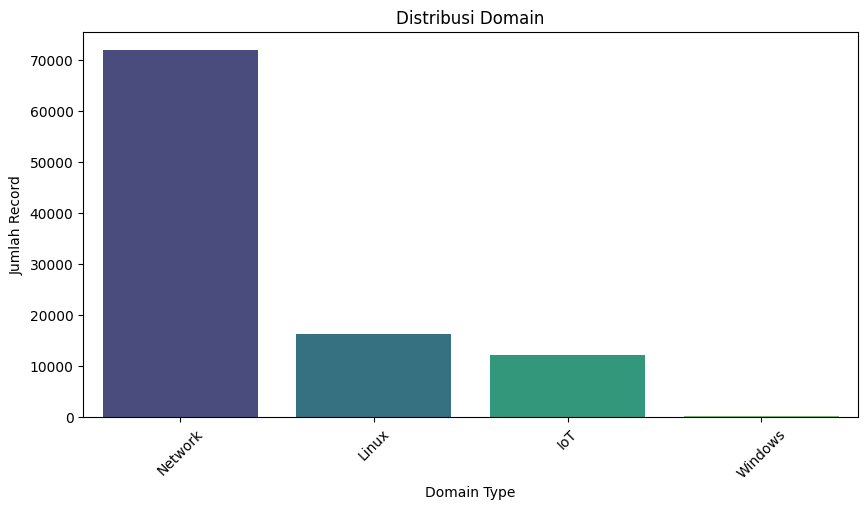

In [14]:
plt.figure(figsize=(10, 5))
domain_counts = pdf["Domain_Type"].value_counts()
sns.barplot(x=domain_counts.index, y=domain_counts.values, palette="viridis")
plt.title("Distribusi Domain")
plt.xlabel("Domain Type")
plt.ylabel("Jumlah Record")
plt.xticks(rotation=45)
plt.savefig("domain_distribution.png", dpi=150)
plt.show()

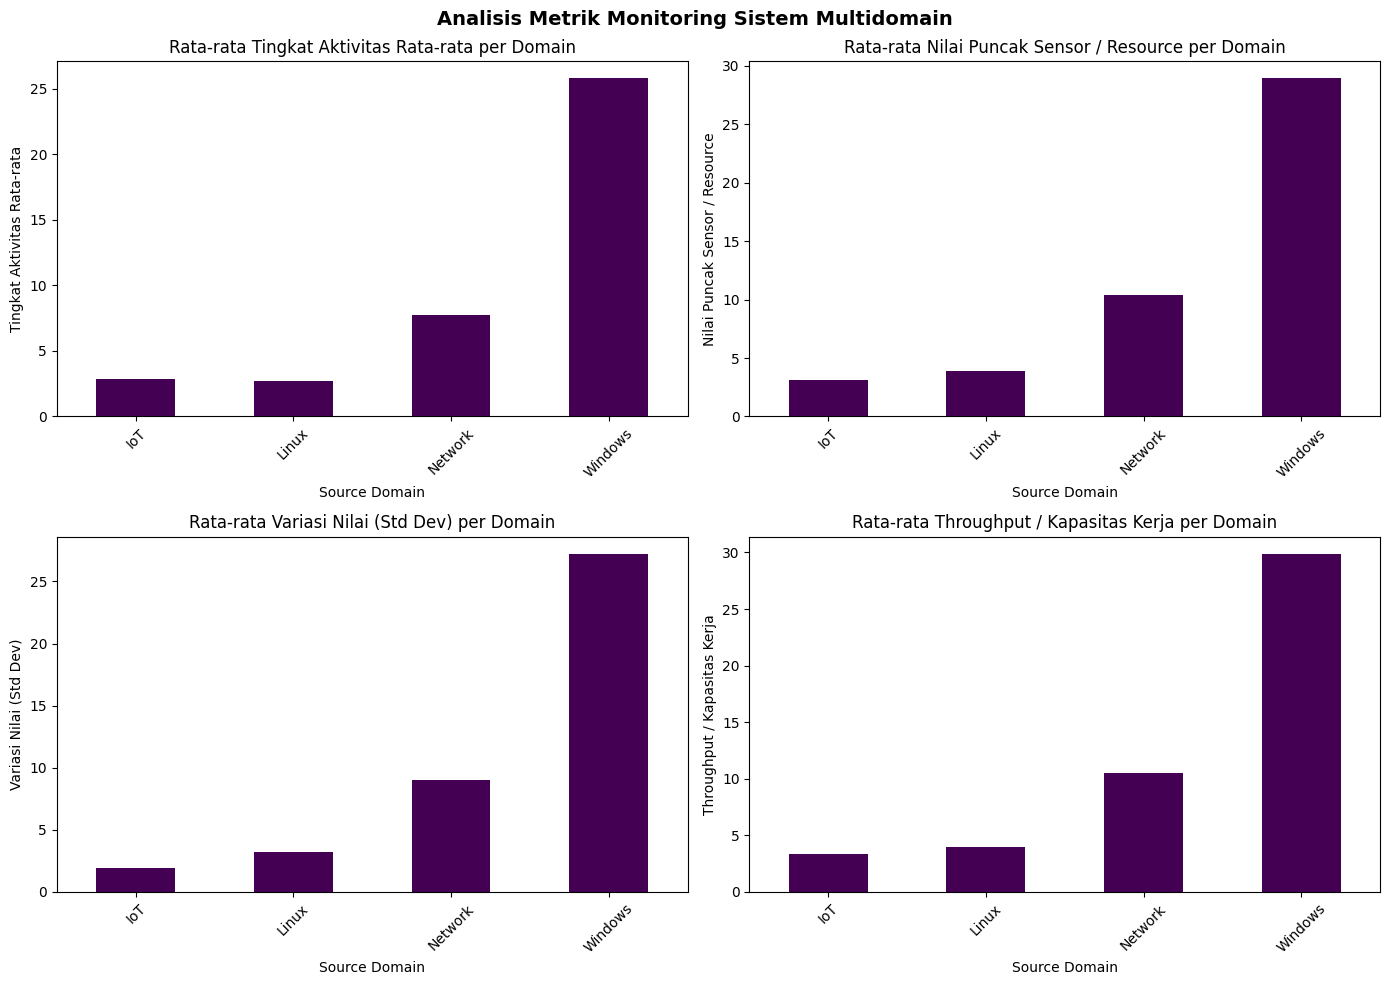

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ["Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric"]
titles = ["Tingkat Aktivitas Rata-rata", "Nilai Puncak Sensor / Resource", "Variasi Nilai (Std Dev)", "Throughput / Kapasitas Kerja"]

for ax, metric, title in zip(axes.flatten(), metrics, titles):
    pdf.groupby("Source_Domain")[metric].mean().plot(kind="bar", ax=ax, colormap="viridis")
    ax.set_title(f"Rata-rata {title} per Domain")
    ax.set_xlabel("Source Domain")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Analisis Metrik Monitoring Sistem Multidomain", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("monitoring_analysis.png", dpi=150)
plt.show()

C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_9016\2095259136.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pdf["Timestamp"] = pd.to_datetime(pdf["Timestamp"], errors="coerce", utc=True)


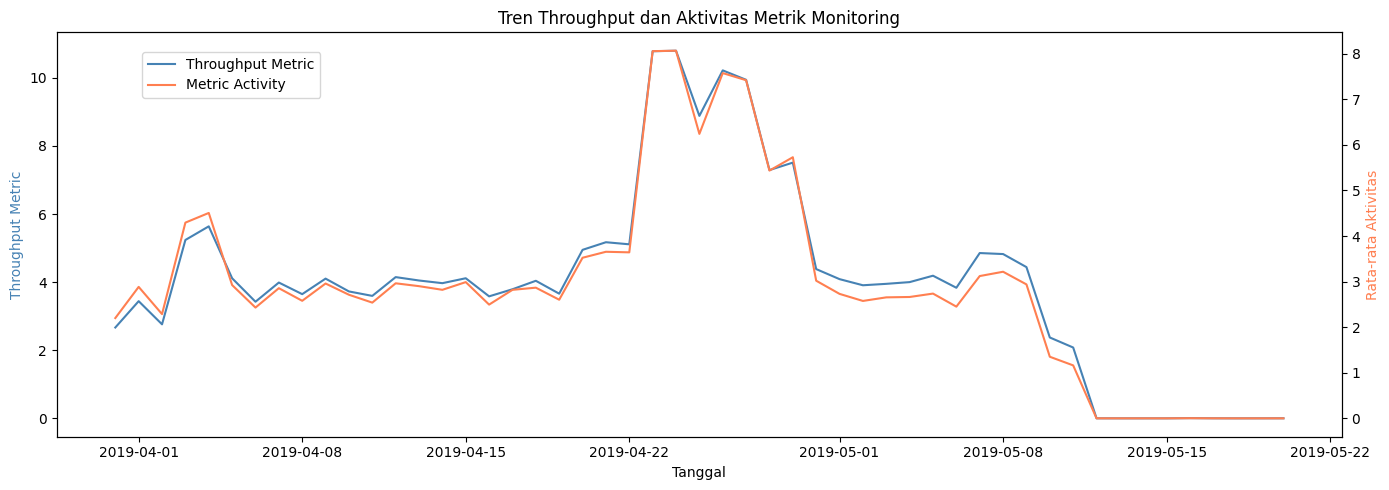

In [16]:
# Normalize mixed timestamp formats/time zones to one pandas datetime dtype.
pdf["Timestamp"] = pd.to_datetime(pdf["Timestamp"], errors="coerce", utc=True)
valid_time = pdf.dropna(subset=["Timestamp"]).copy()
if valid_time.empty:
    pdf_time = pd.DataFrame(columns=["Timestamp", "Throughput_Metric", "Metric_Activity"])
    print("Grafik tren dilewati: tidak ada Timestamp yang dapat diparse pada sample.")
else:
    valid_time["Timestamp"] = valid_time["Timestamp"].dt.floor("D")
    pdf_time = valid_time.groupby("Timestamp", as_index=False).agg({
        "Throughput_Metric": "mean",
        "Metric_Activity": "mean"
    })

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(pdf_time["Timestamp"], pdf_time["Throughput_Metric"], color="steelblue", label="Throughput Metric")
ax1.set_xlabel("Tanggal")
ax1.set_ylabel("Throughput Metric", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(pdf_time["Timestamp"], pdf_time["Metric_Activity"], color="coral", label="Metric Activity")
ax2.set_ylabel("Rata-rata Aktivitas", color="coral")
plt.title("Tren Throughput dan Aktivitas Metrik Monitoring")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.tight_layout()
plt.savefig("monitoring_trend.png", dpi=150)
plt.show()

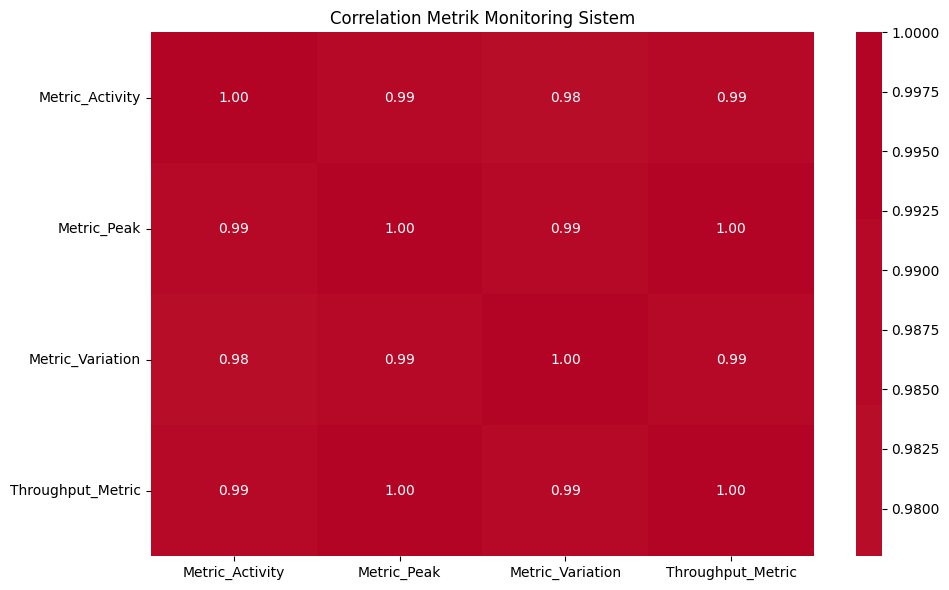

In [17]:
plt.figure(figsize=(10, 6))
numeric_cols = ["Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric"]
corr_matrix = pdf[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Metrik Monitoring Sistem")
plt.tight_layout()
plt.savefig("monitoring_correlation_heatmap.png", dpi=150)
plt.show()

In [18]:
target_cols = ["Target_Label", "Target_Type"]
model_feature_cols = [
    "Metric_Activity",
    "Metric_Peak",
    "Metric_Variation",
    "Throughput_Metric"
]
feature_cols = model_feature_cols

pdf_ml = pdf.copy()
pdf_ml[feature_cols] = (
    pdf_ml[feature_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
)

print(f"Fitur model: {feature_cols}")
print(f"Total record sample model: {len(pdf_ml):,}")
print(f"Distribusi label: {pdf_ml['Target_Label'].value_counts().to_dict()}")

Fitur model: ['Metric_Activity', 'Metric_Peak', 'Metric_Variation', 'Throughput_Metric']
Total record sample model: 100,400
Distribusi label: {1: 73174, 0: 27226}


In [19]:
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features_raw")
df_assembled = assembler.transform(df)

In [20]:
spark_scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=True
)
spark_scaler_model = spark_scaler.fit(df_assembled)
df_scaled = spark_scaler_model.transform(df_assembled)

In [21]:
df_scaled.select("Record_ID", "features").show(5, truncate=False)

+----------------+--------------------------------------------------------------------------------+
|Record_ID       |features                                                                        |
+----------------+--------------------------------------------------------------------------------+
|IoT_Fridge_44651|[-1.9000135688722772,-2.041966235154709,-2.0513099556282337,-2.075038054680302] |
|IoT_Fridge_62585|[-1.235437233762068,-1.518141586569325,-2.0513099556282337,-1.5546015624797622] |
|IoT_Fridge_30523|[-1.6298351227417303,-1.829009314899327,-2.0513099556282337,-1.8634585635913563]|
|IoT_Fridge_90288|[-1.3654655339173818,-1.620630984756693,-2.0513099556282337,-1.6564280477824747]|
|IoT_Fridge_20661|[-1.3459572683996466,-1.605254406041107,-2.0513099556282337,-1.6411509264969522]|
+----------------+--------------------------------------------------------------------------------+
only showing top 5 rows



In [22]:
spark_training = (
    df_scaled
    .select("Record_ID", "features")
    .sample(False, 0.02, seed=RANDOM_STATE)
    .limit(300000)
    .cache()
)
spark_training_count = spark_training.count()
print(f"Data training K-Means Spark: {spark_training_count:,} baris")

inertia = []
k_values = range(2, 8)

for k in k_values:
    kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=k, seed=RANDOM_STATE)
    model = kmeans.fit(spark_training)
    inertia.append(model.summary.trainingCost)
    print(f"K={k}, Inertia={model.summary.trainingCost:.4f}")

Data training K-Means Spark: 300,000 baris


K=2, Inertia=143761.7180


K=3, Inertia=57028.8401


K=4, Inertia=44129.6172


K=5, Inertia=35907.2942


K=6, Inertia=20483.8232


K=7, Inertia=14812.7957


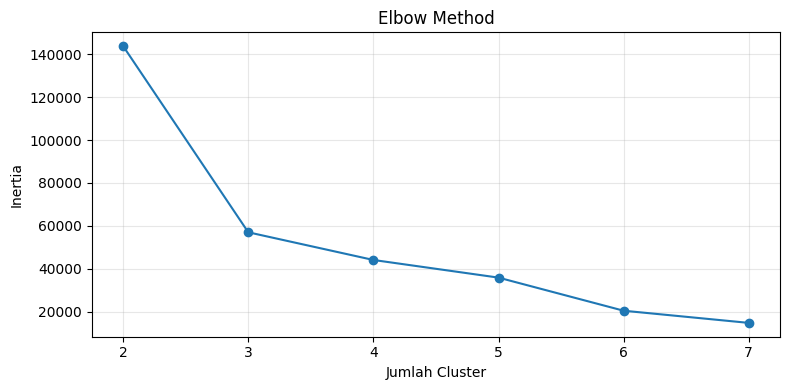

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertia, marker="o")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("elbow_method.png", dpi=150)
plt.show()

In [24]:
# Silhouette-based K selection uses Spark MLlib on the Spark training sample.
evaluator = ClusteringEvaluator(
    featuresCol="features", predictionCol="cluster", metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)
spark_k_scores = {}
for candidate_k in range(2, 7):
    candidate_model = KMeans(
        featuresCol="features", predictionCol="cluster",
        k=candidate_k, seed=RANDOM_STATE
    ).fit(spark_training)
    candidate_predictions = candidate_model.transform(spark_training)
    try:
        spark_k_scores[candidate_k] = evaluator.evaluate(candidate_predictions)
    except Exception as error:
        print(f"Silhouette K={candidate_k} tidak dapat dihitung: {error}")

best_k = max(spark_k_scores, key=spark_k_scores.get) if spark_k_scores else 2
print(f"K terbaik menurut Spark MLlib Silhouette: {best_k}")
print(spark_k_scores)

K terbaik menurut Spark MLlib Silhouette: 2
{2: 0.9378204845810336, 3: 0.9296242663975737, 4: 0.9342232816619828, 5: 0.9005068943724696, 6: 0.8966482771702565}


In [25]:
kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=best_k, seed=RANDOM_STATE)
model = kmeans.fit(spark_training)
df_clustered = model.transform(df_scaled)

In [26]:
eval = ClusteringEvaluator(featuresCol="features", predictionCol="cluster")
silhouette_sample = (
    df_clustered
    .select("features", "cluster")
    .sample(False, 0.02, seed=RANDOM_STATE)
    .limit(100000)
)
silhouette = eval.evaluate(silhouette_sample)
print(f"Silhouette Score Spark Multidomain (sample): {silhouette:.4f}")

Silhouette Score Spark Multidomain (sample): 0.9268


In [27]:
df_clustered.groupBy("cluster").agg(
    F.count("*").alias("Jumlah"),
    F.round(F.avg("Metric_Activity"), 4).alias("Avg_Activity"),
    F.round(F.avg("Metric_Peak"), 4).alias("Avg_Peak"),
    F.round(F.avg("Metric_Variation"), 4).alias("Avg_Variation"),
    F.round(F.avg("Throughput_Metric"), 4).alias("Avg_Throughput")
).orderBy("cluster").show()

+-------+--------+------------+--------+-------------+--------------+
|cluster|  Jumlah|Avg_Activity|Avg_Peak|Avg_Variation|Avg_Throughput|
+-------+--------+------------+--------+-------------+--------------+
|      0|22293589|      7.9421| 10.4675|       9.1077|        10.655|
|      1| 7573019|      1.8444|  2.5854|       1.7417|        2.7328|
+-------+--------+------------+--------+-------------+--------------+



In [28]:
eval = ClusteringEvaluator(featuresCol="features", predictionCol="cluster")
silhouette_sample = (
    df_clustered
    .select("features", "cluster")
    .sample(False, 0.02, seed=RANDOM_STATE)
    .limit(100000)
)
silhouette = eval.evaluate(silhouette_sample)
print(f"Silhouette Score Spark Multidomain (sample): {silhouette:.4f}")

Silhouette Score Spark Multidomain (sample): 0.9268


In [29]:
pdf_clustered = (
    df_clustered.select(
        "Domain_Type",
        "Metric_Activity",
        "Throughput_Metric",
        "cluster"
    )
    .sample(False, 0.01, seed=RANDOM_STATE)
    .limit(100000)
    .toPandas()
)

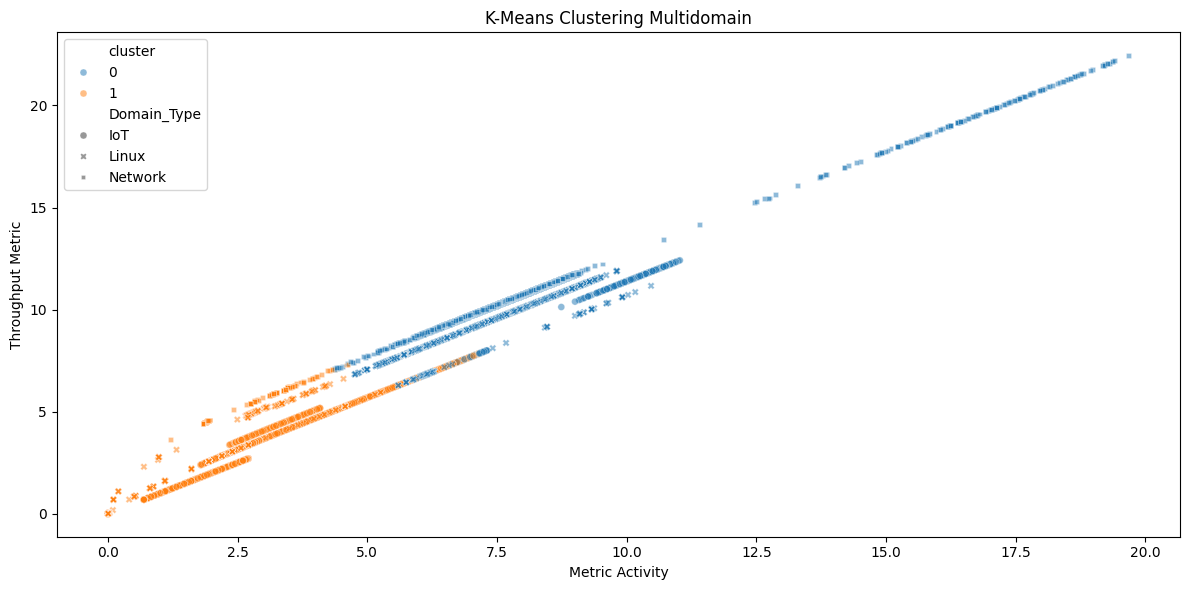

In [30]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=pdf_clustered,
    x="Metric_Activity",
    y="Throughput_Metric",
    hue="cluster",
    style="Domain_Type",
    alpha=0.5,
    s=25
)
plt.xlabel("Metric Activity")
plt.ylabel("Throughput Metric")
plt.title("K-Means Clustering Multidomain")
plt.tight_layout()
plt.savefig("kmeans_clustering.png", dpi=150)
plt.show()

In [31]:
cluster_summary = (
    pdf_clustered.groupby(["Domain_Type", "cluster"])
    .size()
    .reset_index(name="Records")
)
display(cluster_summary)
cluster_summary.to_csv("cluster_summary.csv", index=False)

,Domain_Type,cluster,Records
0,IoT,0,1234
1,IoT,1,12916
2,Linux,0,3743
3,Linux,1,14742
4,Network,0,66800
5,Network,1,565


In [32]:
graph_source = (
    df.select(
        "Device_Type",
        "Source_File",
        "Source_Domain",
        "Domain_Type",
        "System_Region",
        "Metric_Activity",
        "Throughput_Metric",
        "Metric_Peak",
        "Metric_Variation",
    )
    .sample(withReplacement=False, fraction=0.02, seed=42)
    .limit(50_000)
)

try:
    spark.conf.set("spark.sql.shuffle.partitions", "4")

    graph_rows = (
        graph_source
        .groupBy(
            "Device_Type",
            "Source_File",
            "Source_Domain",
            "Domain_Type",
            "System_Region",
        )
        .agg(
            F.avg("Metric_Activity").alias("Metric_Activity"),
            F.avg("Throughput_Metric").alias("Throughput_Metric"),
            F.avg("Metric_Peak").alias("Metric_Peak"),
            F.avg("Metric_Variation").alias("Metric_Variation"),
        )
        .limit(5_000)
        .collect()
    )

    pdf_graph = pd.DataFrame([row.asDict() for row in graph_rows])
    print(f"Berhasil membuat ringkasan grafik: {len(pdf_graph):,} baris")

except Exception as e:
    print(f"Gagal membuat ringkasan grafik: {type(e).__name__}: {e}")
    print("Jika muncul Connection refused atau SparkContext stopped, restart kernel lalu jalankan ulang cell setup Spark dan cell pembentukan df.")
    raise

Berhasil membuat ringkasan grafik: 25 baris


In [33]:
try:
    run_query("MATCH (n) DETACH DELETE n")
    run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (d:Device) REQUIRE d.name IS UNIQUE")
    run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (r:Region) REQUIRE r.name IS UNIQUE")
    run_query("CREATE CONSTRAINT IF NOT EXISTS FOR (dom:Domain) REQUIRE dom.name IS UNIQUE")
    print("Database dibersihkan & constraint dibuat.")
except Exception as error:
    print(f"Neo4j offline saat inisialisasi graph: {error}")

Database dibersihkan & constraint dibuat.


In [34]:
device = pdf_graph.groupby(["Device_Type", "System_Region"]).agg(
    weight=("Throughput_Metric", "mean"),
    activity=("Metric_Activity", "mean"),
    peak=("Metric_Peak", "mean"),
    records=("Throughput_Metric", "count")
).reset_index()

domain = pdf_graph.groupby(["System_Region", "Domain_Type"]).agg(
    weight=("Throughput_Metric", "mean"),
    activity=("Metric_Activity", "mean"),
    records=("Throughput_Metric", "count")
).reset_index()

In [35]:
try:
    for _, row in device.iterrows():
        cypher = """
        MERGE (d:Device {name: $device})
        MERGE (r:Region {name: $region})
        MERGE (d)-[rel:ROUTES_TO]->(r)
        SET rel.weight = $weight, rel.activity = $activity
        """
        run_query(cypher, {
            "device": str(row["Device_Type"]),
            "region": str(row["System_Region"]),
            "weight": float(round(row["weight"], 2)),
            "activity": float(round(row["activity"], 2))
        })
    print("Data Device berhasil diunggah ke Neo4j.")
except Exception as error:
    print(f"Neo4j offline saat upload device: {error}")

Data Device berhasil diunggah ke Neo4j.


In [36]:
try:
    for _, row in domain.iterrows():
        cypher = """
        MERGE (r:Region {name: $region})
        MERGE (dom:Domain {name: $domain})
        MERGE (r)-[rel:SERVES]->(dom)
        SET rel.weight = $weight, rel.activity = $activity
        """
        run_query(cypher, {
            "region": str(row["System_Region"]),
            "domain": str(row["Domain_Type"]),
            "weight": float(round(row["weight"], 2)),
            "activity": float(round(row["activity"], 2))
        })
    print("Data Region dan Domain berhasil diunggah ke Neo4j.")
except Exception as error:
    print(f"Neo4j offline saat upload domain: {error}")

Data Region dan Domain berhasil diunggah ke Neo4j.


In [37]:
try:
    count_nodes = run_query("MATCH (n) RETURN count(n) AS total_nodes")[0]["total_nodes"]
    count_edges = run_query("MATCH ()-[r]->() RETURN count(r) AS total_edges")[0]["total_edges"]
except Exception as error:
    print(f"Neo4j offline saat verifikasi: {error}")
    count_nodes, count_edges = 0, 0

Neo4j offline saat verifikasi: list index out of range


In [38]:
print("Nodes di Neo4j -> ", count_nodes)
print("Edges di Neo4j -> ", count_edges)

Nodes di Neo4j ->  0
Edges di Neo4j ->  0


In [39]:
degree_query = """
MATCH (n)
OPTIONAL MATCH (n)-[r]-()
RETURN n.name AS node, count(r) * 1.0 AS degree
ORDER BY degree DESC
"""
try:
    degree_res = run_query(degree_query)
    max_deg = (count_nodes - 1) if count_nodes > 1 else 1.0
    degree_cent = {r["node"]: r["degree"] / max_deg for r in degree_res if r.get("node")}
    if not degree_cent:
        raise ValueError("Hasil degree query kosong")
except Exception:
    G_temp = nx.DiGraph()
    for _, r in device.iterrows():
        G_temp.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G_temp.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])
    degree_cent = nx.degree_centrality(G_temp)

In [40]:
betweenness_cent = {}
pagerank = {}

try:
    run_query("""
    CALL gds.graph.project.cypher(
        'iotGraph',
        'MATCH (n) RETURN id(n) AS id, labels(n) AS labels',
        'MATCH (s)-[r]->(t) RETURN id(s) AS source, id(t) AS target, type(r) AS type, r.weight AS weight'
    )
    """)

    pr_records = run_query("CALL gds.pageRank.stream('iotGraph') YIELD nodeId, score RETURN gds.util.asNode(nodeId).name AS node, score")
    pagerank = {r["node"]: r["score"] for r in pr_records if r.get("node")}
    
    bw_records = run_query("CALL gds.betweenness.stream('iotGraph') YIELD nodeId, score RETURN gds.util.asNode(nodeId).name AS node, score")
    betweenness_cent = {r["node"]: r["score"] for r in bw_records if r.get("node")}
    if not (betweenness_cent and pagerank):
        raise ValueError("Hasil GDS kosong")
    print("Graph Analytics berhasil dihitung menggunakan Neo4j GDS Plugin!")
except Exception:
    G_net = nx.DiGraph()
    try:
        edges_data = run_query("MATCH (a)-[r]->(b) RETURN a.name AS source, b.name AS target, r.weight AS weight")
    except Exception:
        edges_data = []

    if edges_data:
        for edge in edges_data:
            G_net.add_edge(edge["source"], edge["target"], weight=edge.get("weight", 1.0))
    else:
        for _, r in device.iterrows():
            G_net.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
        for _, r in domain.iterrows():
            G_net.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])

    betweenness_cent = nx.betweenness_centrality(G_net)
    pagerank = nx.pagerank(G_net, weight="weight")
    if not degree_cent:
        degree_cent = nx.degree_centrality(G_net)
    print("Graph Analytics berhasil dihitung menggunakan NetworkX fallback!")

Graph Analytics berhasil dihitung menggunakan NetworkX fallback!


In [41]:
for node, score in sorted(degree_cent.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Network_Gateway_Core: 0.4667
IoT_Smart_Environment: 0.2667
Linux_Host_Cluster: 0.2000
IoT_Fridge: 0.0333
IoT_GPS_Tracker: 0.0333
IoT_Garage_Door: 0.0333
IoT_Modbus: 0.0333
IoT_Motion_Light: 0.0333
IoT_Thermostat: 0.0333
IoT_Weather: 0.0333
Linux_process_1: 0.0333
Linux_process_2: 0.0333
Network_dataset_1: 0.0333
Network_dataset_10: 0.0333
Network_dataset_11: 0.0333
Network_dataset_12: 0.0333
Network_dataset_13: 0.0333
Network_dataset_14: 0.0333
Network_dataset_15: 0.0333
Network_dataset_16: 0.0333
Network_dataset_17: 0.0333
Network_dataset_18: 0.0333
Network_dataset_19: 0.0333
Network_dataset_2: 0.0333
Network_dataset_20: 0.0333
linux_disk_2: 0.0333
linux_memory1: 0.0333
linux_memory2: 0.0333
IoT: 0.0333
Linux: 0.0333
Network: 0.0333


In [42]:
for node, score in sorted(betweenness_cent.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Network_Gateway_Core: 0.0149
IoT_Smart_Environment: 0.0080
Linux_Host_Cluster: 0.0057
IoT_Fridge: 0.0000
IoT_GPS_Tracker: 0.0000
IoT_Garage_Door: 0.0000
IoT_Modbus: 0.0000
IoT_Motion_Light: 0.0000
IoT_Thermostat: 0.0000
IoT_Weather: 0.0000
Linux_process_1: 0.0000
Linux_process_2: 0.0000
Network_dataset_1: 0.0000
Network_dataset_10: 0.0000
Network_dataset_11: 0.0000
Network_dataset_12: 0.0000
Network_dataset_13: 0.0000
Network_dataset_14: 0.0000
Network_dataset_15: 0.0000
Network_dataset_16: 0.0000
Network_dataset_17: 0.0000
Network_dataset_18: 0.0000
Network_dataset_19: 0.0000
Network_dataset_2: 0.0000
Network_dataset_20: 0.0000
linux_disk_2: 0.0000
linux_memory1: 0.0000
linux_memory2: 0.0000
IoT: 0.0000
Linux: 0.0000
Network: 0.0000


In [43]:
for node, score in sorted(pagerank.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Network_Gateway_Core: 0.1690
Network: 0.1577
IoT: 0.0868
IoT_Smart_Environment: 0.0856
Linux: 0.0766
Linux_Host_Cluster: 0.0736
IoT_Fridge: 0.0140
IoT_GPS_Tracker: 0.0140
IoT_Garage_Door: 0.0140
IoT_Modbus: 0.0140
IoT_Motion_Light: 0.0140
IoT_Thermostat: 0.0140
IoT_Weather: 0.0140
Linux_process_1: 0.0140
Linux_process_2: 0.0140
Network_dataset_1: 0.0140
Network_dataset_10: 0.0140
Network_dataset_11: 0.0140
Network_dataset_12: 0.0140
Network_dataset_13: 0.0140
Network_dataset_14: 0.0140
Network_dataset_15: 0.0140
Network_dataset_16: 0.0140
Network_dataset_17: 0.0140
Network_dataset_18: 0.0140
Network_dataset_19: 0.0140
Network_dataset_2: 0.0140
Network_dataset_20: 0.0140
linux_disk_2: 0.0140
linux_memory1: 0.0140
linux_memory2: 0.0140


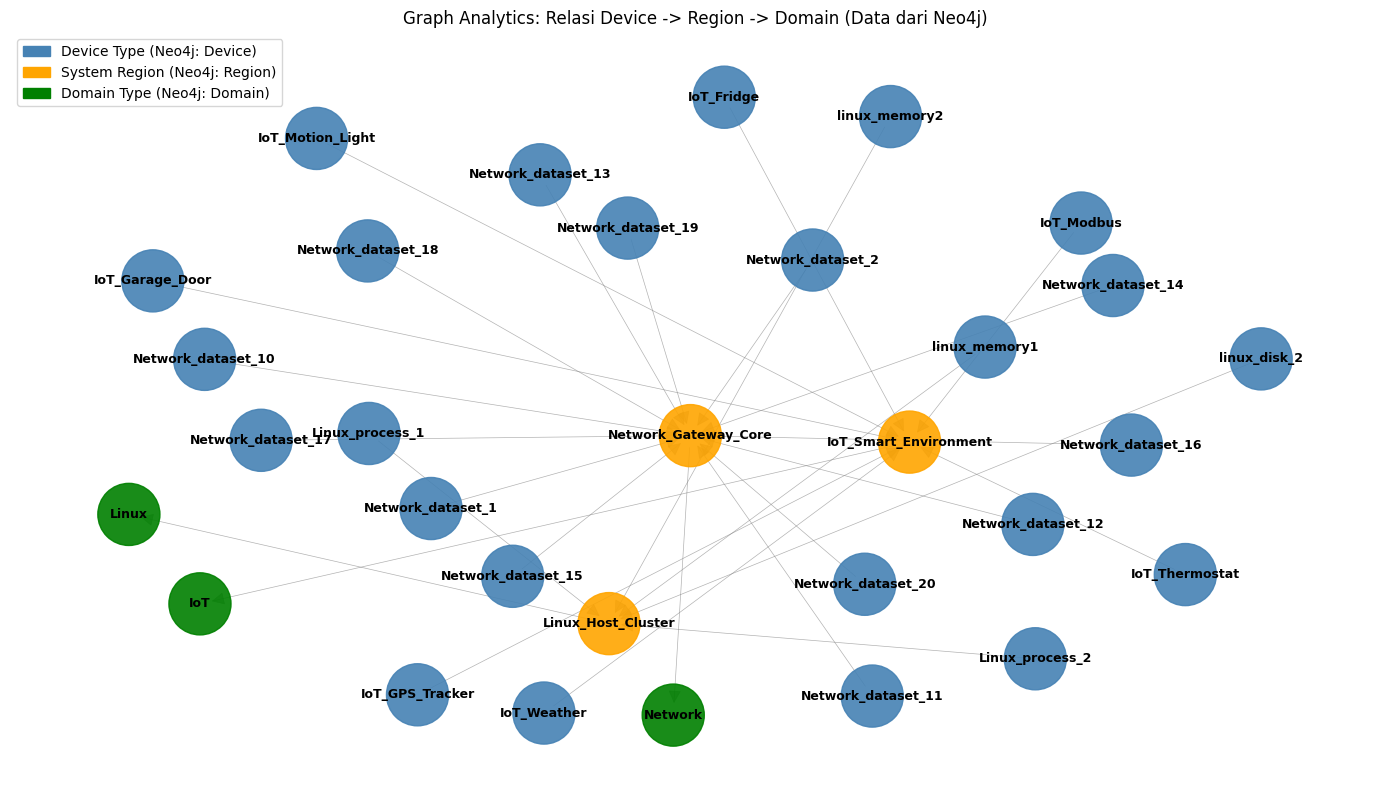

In [44]:
import networkx as nx
from matplotlib.patches import Patch

try:
    edges_data = run_query("""
    MATCH (a)-[r]->(b)
    RETURN a.name AS source, labels(a)[0] AS source_label, 
           b.name AS target, labels(b)[0] AS target_label, 
           r.weight AS weight
    """)
except Exception:
    edges_data = []

G = nx.DiGraph()
if edges_data:
    for edge in edges_data:
        G.add_edge(edge["source"], edge["target"], weight=edge["weight"])
else:
    for _, r in device.iterrows():
        G.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])

plt.figure(figsize=(14, 8))
color_map = []
for node in G.nodes():
    if node in pdf_graph["Device_Type"].values:
        color_map.append("steelblue")
    elif node in pdf_graph["System_Region"].values:
        color_map.append("orange")
    else:
        color_map.append("green")

pos = nx.spring_layout(G, seed=42, k=2)
weights = [max(0.5, G[u][v].get("weight", 1.0) / 100) for u, v in G.edges()]
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=2000, alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
nx.draw_networkx_edges(G, pos, width=weights, alpha=0.6, arrows=True, arrowsize=20, edge_color="gray")
legend = [
    Patch(color="steelblue", label="Device Type (Neo4j: Device)"),
    Patch(color="orange", label="System Region (Neo4j: Region)"),
    Patch(color="green", label="Domain Type (Neo4j: Domain)")
]
plt.legend(handles=legend, loc="upper left")
plt.title("Graph Analytics: Relasi Device -> Region -> Domain (Data dari Neo4j)")
plt.axis("off")
plt.tight_layout()
plt.savefig("graph_analytics.png", dpi=150)
plt.show()

In [45]:
if not betweenness_cent:
    G_fallback = nx.DiGraph()
    for _, r in device.iterrows():
        G_fallback.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G_fallback.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])
    betweenness_cent = nx.betweenness_centrality(G_fallback)
    pagerank = nx.pagerank(G_fallback, weight="weight")

top_node = max(betweenness_cent, key=betweenness_cent.get)
print(f"Node paling kritis (Jalur Penghubung Utama): {top_node}")
print(f"Betweenness Centrality: {betweenness_cent[top_node]:.4f}")
print(f"PageRank: {pagerank[top_node]:.4f}")

Node paling kritis (Jalur Penghubung Utama): Network_Gateway_Core
Betweenness Centrality: 0.0149
PageRank: 0.1690


In [46]:
nodes_union = list(set(list(degree_cent.keys()) + list(betweenness_cent.keys()) + list(pagerank.keys())))
cent_df = pd.DataFrame({
    "Node": nodes_union,
    "Degree": [degree_cent.get(k, 0.0) for k in nodes_union],
    "Betweenness": [betweenness_cent.get(k, 0.0) for k in nodes_union],
    "PageRank": [pagerank.get(k, 0.0) for k in nodes_union]
}).sort_values("Betweenness", ascending=False)
cent_df.head(10)

,Node,Degree,Betweenness,PageRank
8,Network_Gateway_Core,0.466667,0.014943,0.169026
12,IoT_Smart_Environment,0.266667,0.008046,0.085565
11,Linux_Host_Cluster,0.200000,0.005747,0.073642
23,Network_dataset_20,0.033333,0.000000,0.014027
19,Network_dataset_15,0.033333,0.000000,0.014027
20,Network_dataset_18,0.033333,0.000000,0.014027
21,Network_dataset_16,0.033333,0.000000,0.014027
22,Linux_process_2,0.033333,0.000000,0.014027
0,Network_dataset_1,0.033333,0.000000,0.014027
17,linux_memory2,0.033333,0.000000,0.014027


C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_9016\575621910.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_9016\575621910.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
C:\Users\Jase.LAPTOP-UM736EL9\AppData\Local\Temp\ipykernel_9016\575621910.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax

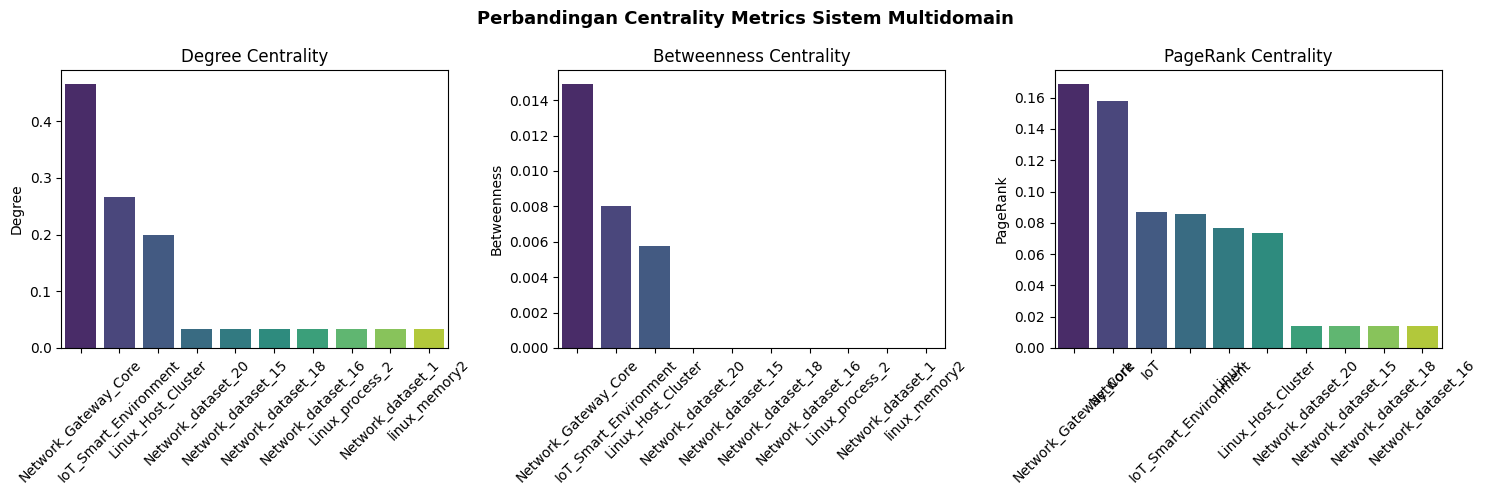

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ["Degree", "Betweenness", "PageRank"]

for ax, metric in zip(axes, metrics):
    top10 = cent_df.nlargest(10, metric)
    sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
    ax.set_title(f"{metric} Centrality")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Perbandingan Centrality Metrics Sistem Multidomain", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("centrality_analysis.png", dpi=150)
plt.show()

In [48]:
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, IndexToString
from pyspark.ml.clustering import KMeans
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F
from sklearn.ensemble import IsolationForest, RandomForestClassifier as SklearnRandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler as SklearnStandardScaler
from sklearn.cluster import KMeans as SklearnKMeans
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, confusion_matrix
)
import random
import joblib
import shutil

MODEL_TEST_SIZE = 0.2
MODEL_RANDOM_STATE = 42
MODEL_N_ESTIMATORS = 200
MODEL_ANOMALY_QUANTILE = 0.95
MODEL_MAX_TRAIN_ROWS = 300000

In [49]:
def _safe_binary_metrics(scored_df, label_col="Target_Label", prediction_col="prediction", score_col="positive_score"):
    row = scored_df.agg(
        F.sum(F.when((F.col(label_col) == 1) & (F.col(prediction_col) == 1), 1).otherwise(0)).alias("tp"),
        F.sum(F.when((F.col(label_col) == 0) & (F.col(prediction_col) == 0), 1).otherwise(0)).alias("tn"),
        F.sum(F.when((F.col(label_col) == 0) & (F.col(prediction_col) == 1), 1).otherwise(0)).alias("fp"),
        F.sum(F.when((F.col(label_col) == 1) & (F.col(prediction_col) == 0), 1).otherwise(0)).alias("fn"),
        F.count(F.lit(1)).alias("n")
    ).first()
    tp, tn, fp, fn, n = [int(row[k] or 0) for k in ("tp", "tn", "fp", "fn", "n")]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    metrics = {
        "Accuracy": (tp + tn) / n if n else 0.0,
        "Balanced_Accuracy": (recall + specificity) / 2 if n else 0.0,
        "Precision": precision, "Recall": recall, "F1": f1,
        "Average_Precision": np.nan,
        "_confusion": [[tn, fp], [fn, tp]],
        "_positive_rate": (tp + fn) / n if n else 0.0,
        "_predicted_positive_rate": (tp + fp) / n if n else 0.0,
        "_count": n
    }
    if tp + fn > 0 and tn + fp > 0 and "probability" in scored_df.columns:
        try:
            metrics["Average_Precision"] = float(BinaryClassificationEvaluator(
                labelCol=label_col, rawPredictionCol="probability", metricName="areaUnderPR"
            ).evaluate(scored_df))
        except Exception as error:
            print(f"Average precision dilewati: {error}")
    return metrics


def _split_spark_by_source(data):
    source_files = [r[0] for r in data.select("Source_File").distinct().where(F.col("Source_File").isNotNull()).collect()]
    if len(source_files) >= 3:
        random.Random(MODEL_RANDOM_STATE).shuffle(source_files)
        n_test_files = max(1, min(len(source_files) - 1, round(len(source_files) * MODEL_TEST_SIZE)))
        test_files = source_files[:n_test_files]
        train = data.where(~F.col("Source_File").isin(test_files))
        test = data.where(F.col("Source_File").isin(test_files))
        if train.limit(1).count() and test.limit(1).count():
            return train, test, "held-out source files"
    train, test = data.randomSplit([1.0 - MODEL_TEST_SIZE, MODEL_TEST_SIZE], seed=MODEL_RANDOM_STATE)
    return train, test, "random row split (source-file holdout unavailable)"


def _with_squared_centroid_distance(scored, kmeans_model, features_col="scaled_features"):
    centers = kmeans_model.clusterCenters()
    centers_expr = F.array(*[
        F.array(*[F.lit(float(value)) for value in center.tolist()])
        for center in centers
    ])
    nearest_center = F.element_at(centers_expr, F.col("cluster") + F.lit(1))
    differences = F.zip_with(vector_to_array(F.col(features_col)), nearest_center, lambda x, y: (x - y) * (x - y))
    return scored.withColumn("anomaly_score", F.aggregate(differences, F.lit(0.0), lambda acc, value: acc + value))


def train_domain_model(domain_name, source_df, models_dir):
    prefix = domain_name.lower()
    selected_cols = list(dict.fromkeys([
        "Record_ID", "Source_File", "Domain_Type", "Target_Label", "Target_Type",
        "Metric_Activity", "Throughput_Metric", *feature_cols
    ]))
    data = source_df.select(*selected_cols).where(F.col("Target_Label").isNotNull())
    data = data.na.fill(0.0, subset=feature_cols)
    for feature_name in feature_cols:
        data = data.withColumn(feature_name, F.when(F.isnan(F.col(feature_name)) | (F.abs(F.col(feature_name)) == F.lit(float("inf"))), 0.0).otherwise(F.col(feature_name)))
    data = data.withColumn("Target_Label", F.col("Target_Label").cast("double"))
    data = data.withColumn("_model_key", F.concat_ws("::", F.col("Domain_Type"), F.col("Source_File"), F.col("Record_ID")))
    total_count = data.count()
    if total_count < 4:
        raise ValueError(f"{domain_name}: baris berlabel terlalu sedikit untuk split train/test ({total_count}).")

    train_df, test_df, split_method = _split_spark_by_source(data)
    train_count, test_count = train_df.count(), test_df.count()
    best_k_local = min(best_k if "best_k" in globals() else 4, max(2, train_count - 1))
    if train_count < 2 or test_count < 1:
        raise ValueError(f"{domain_name}: split menghasilkan data train/test tidak cukup.")

    # Both frameworks receive these exact same train/test records for a fair comparison.
    sklearn_cols = list(dict.fromkeys(["Source_File", "Domain_Type", "Target_Label", "Target_Type", *feature_cols]))
    train_pd = train_df.select(*sklearn_cols).toPandas()
    test_pd = test_df.select(*sklearn_cols).toPandas()
    X_sk_train = train_pd[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=float)
    X_sk_test = test_pd[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=float)
    y_sk_train = train_pd["Target_Label"].astype(int).to_numpy()
    y_sk_test = test_pd["Target_Label"].astype(int).to_numpy()

    def _sk_metrics(y_true, y_pred, scores=None):
        return {
            "Accuracy": float(accuracy_score(y_true, y_pred)),
            "Balanced_Accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
            "F1": float(f1_score(y_true, y_pred, zero_division=0)),
            "Average_Precision": float(average_precision_score(y_true, scores))
                if scores is not None and len(np.unique(y_true)) > 1 else np.nan
        }

    sklearn_scaler = SklearnStandardScaler()
    X_sk_train_scaled = sklearn_scaler.fit_transform(X_sk_train)
    X_sk_test_scaled = sklearn_scaler.transform(X_sk_test)
    sklearn_kmeans = SklearnKMeans(n_clusters=best_k_local, random_state=MODEL_RANDOM_STATE, n_init=10)
    sklearn_kmeans.fit(X_sk_train_scaled)
    sklearn_clusters = sklearn_kmeans.predict(X_sk_test_scaled)

    if len(np.unique(y_sk_train)) >= 2:
        sklearn_classifier = SklearnRandomForestClassifier(
            n_estimators=MODEL_N_ESTIMATORS, min_samples_leaf=2, max_depth=12,
            class_weight="balanced_subsample", random_state=MODEL_RANDOM_STATE, n_jobs=-1
        )
    else:
        sklearn_classifier = DummyClassifier(strategy="most_frequent")
    sklearn_classifier.fit(X_sk_train, y_sk_train)
    sklearn_prediction = sklearn_classifier.predict(X_sk_test).astype(int)
    sklearn_classes = list(sklearn_classifier.classes_)
    sklearn_scores = (
        sklearn_classifier.predict_proba(X_sk_test)[:, sklearn_classes.index(1)]
        if 1 in sklearn_classes and hasattr(sklearn_classifier, "predict_proba")
        else np.zeros(len(X_sk_test), dtype=float)
    )
    sklearn_metrics = _sk_metrics(y_sk_test, sklearn_prediction, sklearn_scores)
    sklearn_confusion = confusion_matrix(y_sk_test, sklearn_prediction, labels=[0, 1]).tolist()

    sklearn_iso = IsolationForest(
        n_estimators=MODEL_N_ESTIMATORS, contamination=0.05,
        random_state=MODEL_RANDOM_STATE, n_jobs=-1
    ).fit(X_sk_train_scaled)
    sklearn_iso_prediction = (sklearn_iso.predict(X_sk_test_scaled) == -1).astype(int)
    sklearn_iso_scores = -sklearn_iso.decision_function(X_sk_test_scaled)
    sklearn_iso_metrics = _sk_metrics(y_sk_test, sklearn_iso_prediction, sklearn_iso_scores)
    sklearn_type_classifier = None
    sklearn_type_prediction = np.repeat("unknown", len(test_pd)).astype(str)
    y_type_train = train_pd["Target_Type"].fillna("unknown").astype(str).str.lower().to_numpy()
    y_type_test = test_pd["Target_Type"].fillna("unknown").astype(str).str.lower().to_numpy()
    if len(np.unique(y_type_train)) >= 2:
        sklearn_type_classifier = SklearnRandomForestClassifier(
            n_estimators=MODEL_N_ESTIMATORS, min_samples_leaf=2, max_depth=12,
            class_weight="balanced_subsample", random_state=MODEL_RANDOM_STATE, n_jobs=-1
        ).fit(X_sk_train, y_type_train)
        sklearn_type_prediction = sklearn_type_classifier.predict(X_sk_test).astype(str)
    else:
        sklearn_type_prediction = np.repeat(y_type_train[0] if len(y_type_train) else "unknown", len(test_pd)).astype(str)
    sklearn_attack_counts = (
        pd.DataFrame({"Target_Type": y_type_test, "Predicted_Type": sklearn_type_prediction})
        .groupby(["Target_Type", "Predicted_Type"]).size().reset_index(name="count")
        .itertuples(index=False, name=None)
    )
    sklearn_attack_counts = [(str(actual), str(predicted), int(count)) for actual, predicted, count in sklearn_attack_counts]
    sklearn_plot_data = test_pd.copy()
    sklearn_plot_data["IF_Anomaly"] = sklearn_iso_prediction
    sklearn_plot_data["KMeans_Cluster"] = sklearn_clusters
    if len(sklearn_plot_data) > 5000:
        sklearn_plot_data = sklearn_plot_data.sample(n=5000, random_state=MODEL_RANDOM_STATE)
    joblib.dump(sklearn_scaler, models_dir / f"{prefix}_sklearn_scaler.pkl")
    joblib.dump(sklearn_kmeans, models_dir / f"{prefix}_sklearn_kmeans.pkl")
    joblib.dump(sklearn_classifier, models_dir / f"{prefix}_sklearn_random_forest.pkl")
    joblib.dump(sklearn_iso, models_dir / f"{prefix}_sklearn_isolation_forest.pkl")
    if sklearn_type_classifier is not None:
        joblib.dump(sklearn_type_classifier, models_dir / f"{prefix}_sklearn_attack_type.pkl")

    assembler = VectorAssembler(inputCols=feature_cols, outputCol="raw_features", handleInvalid="keep")
    assembled_train = assembler.transform(train_df)
    assembled_test = assembler.transform(test_df)
    scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withStd=True, withMean=True)
    scaler_model = scaler.fit(assembled_train)
    scaled_train = scaler_model.transform(assembled_train).cache()
    scaled_test = scaler_model.transform(assembled_test).cache()

    # MLlib K-Means serves both clustering and distance-based anomaly scoring.
    cluster_fit = scaled_train.select("scaled_features").limit(MODEL_MAX_TRAIN_ROWS)
    kmeans_model = KMeans(
        featuresCol="scaled_features", predictionCol="cluster", k=best_k_local,
        seed=MODEL_RANDOM_STATE
    ).fit(cluster_fit)
    train_distances = _with_squared_centroid_distance(kmeans_model.transform(scaled_train), kmeans_model)
    test_clustered = _with_squared_centroid_distance(kmeans_model.transform(scaled_test), kmeans_model)
    threshold_values = train_distances.approxQuantile("anomaly_score", [MODEL_ANOMALY_QUANTILE], 0.005)
    anomaly_threshold = float(threshold_values[0]) if threshold_values else 0.0
    test_clustered = test_clustered.withColumn(
        "anomaly_prediction", F.when(F.col("anomaly_score") > F.lit(anomaly_threshold), 1.0).otherwise(0.0)
    )
    anomaly_scored = test_clustered.withColumnRenamed("anomaly_prediction", "prediction")
    anomaly_metrics = _safe_binary_metrics(anomaly_scored)
    anomaly_counts = test_clustered.agg(
        F.sum(F.when(F.col("anomaly_prediction") == 1, 1).otherwise(0)).alias("anomaly"),
        F.sum(F.when(F.col("anomaly_prediction") == 0, 1).otherwise(0)).alias("normal")
    ).first()

    class_counts = {int(r["Target_Label"]): int(r["count"]) for r in train_df.groupBy("Target_Label").count().collect()}
    total_train = sum(class_counts.values())
    n_classes = max(len(class_counts), 1)
    weighted_train = train_df.withColumn(
        "class_weight",
        F.when(F.col("Target_Label") == 1.0, F.lit(total_train / (n_classes * max(class_counts.get(1, 0), 1))))
         .otherwise(F.lit(total_train / (n_classes * max(class_counts.get(0, 0), 1))))
    )
    classifier_assembler = VectorAssembler(inputCols=feature_cols, outputCol="features", handleInvalid="keep")
    classifier_train = classifier_assembler.transform(weighted_train)
    classifier_test = classifier_assembler.transform(test_df)
    if len(class_counts) >= 2:
        classifier = RandomForestClassifier(
            labelCol="Target_Label", featuresCol="features", weightCol="class_weight",
            numTrees=MODEL_N_ESTIMATORS, maxDepth=12, maxBins=64,
            minInstancesPerNode=2, seed=MODEL_RANDOM_STATE
        ).fit(classifier_train)
        test_scored = classifier.transform(classifier_test).withColumn(
            "positive_score", vector_to_array(F.col("probability"))[1]
        ).cache()
    else:
        # A domain with a single training label cannot fit a binary RF; report its constant baseline explicitly.
        only_class = float(next(iter(class_counts)))
        classifier = None
        test_scored = classifier_assembler.transform(test_df).withColumn("prediction", F.lit(only_class))
    classifier_metrics = _safe_binary_metrics(test_scored)

    type_indexer = StringIndexer(inputCol="Target_Type", outputCol="type_label", handleInvalid="keep")
    type_indexer_model = type_indexer.fit(data)
    indexed_train = type_indexer_model.transform(train_df)
    indexed_test = type_indexer_model.transform(test_df)
    type_prediction_col = F.lit("normal").alias("type_prediction")
    type_classifier = None
    if len(type_indexer_model.labels) >= 2 and indexed_train.select("type_label").distinct().count() >= 2:
        type_features_train = classifier_assembler.transform(indexed_train)
        type_features_test = classifier_assembler.transform(indexed_test)
        type_classifier = RandomForestClassifier(
            labelCol="type_label", featuresCol="features", numTrees=MODEL_N_ESTIMATORS,
            maxDepth=12, maxBins=64, minInstancesPerNode=2, seed=MODEL_RANDOM_STATE
        ).fit(type_features_train)
        type_prediction_col = IndexToString(
            inputCol="type_prediction_index", outputCol="type_prediction",
            labels=type_indexer_model.labels
        )
        typed_test = type_classifier.transform(type_features_test).withColumnRenamed("prediction", "type_prediction_index")
        typed_test = type_prediction_col.transform(typed_test).withColumnRenamed("type_prediction", "Predicted_Type")
        type_predictions = typed_test.select("_model_key", "Predicted_Type")
    else:
        type_predictions = indexed_test.select("_model_key", F.lit(type_indexer_model.labels[0] if type_indexer_model.labels else "unknown").alias("Predicted_Type"))

    model_root = models_dir / f"{prefix}_mllib"
    model_root.mkdir(parents=True, exist_ok=True)
    mllib_artifacts = [
        ("scaler", scaler_model),
        ("kmeans", kmeans_model),
        ("random_forest_binary", classifier),
        ("target_type_indexer", type_indexer_model),
        ("random_forest_attack_type", type_classifier),
    ]
    for artifact_name, artifact_model in mllib_artifacts:
        if artifact_model is None:
            continue
        try:
            target = model_root / artifact_name
            # Spark/Hadoop di Windows salah menangani path lokal yang mengandung spasi
            # saat fs.defaultFS bukan file://. Simpan ke path aman lalu salin ke tujuan.
            if any(ch in str(target.resolve()) for ch in (" ",)):
                safe_root = Path("C:/sparktmp") / f"{prefix}_mllib"
                safe_target = safe_root / artifact_name
                safe_target.parent.mkdir(parents=True, exist_ok=True)
                artifact_model.write().overwrite().save(
                    "file:///" + str(safe_target.resolve()).replace("\\", "/")
                )
                if target.exists():
                    shutil.rmtree(target)
                shutil.copytree(safe_target, target)
            else:
                artifact_model.write().overwrite().save("file:///" + str(target.resolve()).replace("\\", "/"))
        except Exception as error:
            message = str(error).splitlines()[0] if str(error) else repr(error)
            print(f"Gagal menyimpan artefak MLlib {prefix}/{artifact_name}: {type(error).__name__}: {message[:500]}")

    confusion = classifier_metrics.pop("_confusion")
    positive_rate = classifier_metrics.pop("_positive_rate")
    predicted_rate = classifier_metrics.pop("_predicted_positive_rate")
    evaluated_count = classifier_metrics.pop("_count")
    anomaly_confusion = anomaly_metrics.pop("_confusion")
    anomaly_metrics.pop("_positive_rate")
    anomaly_metrics.pop("_predicted_positive_rate")
    anomaly_metrics.pop("_count")

    attack_metrics = typed_test.groupBy("Target_Type", "Predicted_Type").count().collect() if type_classifier is not None else []
    type_actual = [r["Target_Type"] for r in attack_metrics]
    type_predicted = [r["Predicted_Type"] for r in attack_metrics]
    type_counts = [(r["Target_Type"], r["Predicted_Type"], int(r["count"])) for r in attack_metrics]

    plot_data = (
        test_scored.join(test_clustered.select("_model_key", "anomaly_prediction", "cluster", "anomaly_score"), "_model_key")
        .join(type_predictions, "_model_key", "left")
        .select("Metric_Activity", "Throughput_Metric", "Domain_Type", "Target_Label", "Target_Type",
                "Predicted_Type", "prediction", "anomaly_prediction", "anomaly_score", "cluster")
        .sample(False, min(1.0, 5000.0 / max(test_count, 1)), seed=MODEL_RANDOM_STATE)
        .limit(5000).toPandas()
    )
    if not plot_data.empty:
        plot_data["test_anomaly"] = np.where(plot_data["anomaly_prediction"] == 1, -1, 1)

    metrics_out = {k: float(v) for k, v in classifier_metrics.items()}
    anomaly_metrics_out = {k: float(v) for k, v in anomaly_metrics.items()}
    with open(models_dir / f"{prefix}_mllib_metadata.json", "w", encoding="utf-8") as file:
        json.dump({
            "framework": "Apache Spark MLlib", "features": feature_cols,
            "split": split_method, "k": int(best_k_local),
            "anomaly_method": "K-Means squared distance; threshold fitted on train quantile",
            "anomaly_quantile": MODEL_ANOMALY_QUANTILE,
            "anomaly_threshold": anomaly_threshold,
            "attack_type_labels": list(type_indexer_model.labels)
        }, file, indent=2)

    result = {
        "Domain": domain_name, "Records": total_count, "Train": train_count, "Test": test_count,
        "Split": split_method, "Best_K": int(best_k_local),
        "Train_Silhouette": np.nan, "Test_Silhouette": np.nan,
        "Positive_Rate": positive_rate, "Predicted_Anomaly_Rate": predicted_rate,
        **metrics_out,
        "MLlib_Accuracy": metrics_out["Accuracy"],
        "MLlib_Balanced_Accuracy": metrics_out["Balanced_Accuracy"],
        "MLlib_Precision": metrics_out["Precision"],
        "MLlib_Recall": metrics_out["Recall"],
        "MLlib_F1": metrics_out["F1"],
        **{f"KMeans_Anomaly_{key}": value for key, value in anomaly_metrics_out.items()},
        "Anomaly_Count": int(anomaly_counts["anomaly"] or 0),
        "Normal_Count": int(anomaly_counts["normal"] or 0),
        "Anomaly_Confusion": anomaly_confusion,
        "Confusion": confusion,
        "Attack_Type_Counts": type_counts,
        "Attack_Type_Actual": type_actual,
        "Attack_Type_Predicted": type_predicted,
        "plot_data": plot_data,
        "scaler": scaler_model, "kmeans": kmeans_model,
        "classifier": classifier, "type_classifier": type_classifier,
        "anomaly_threshold": anomaly_threshold,
        "framework": "Spark MLlib + scikit-learn comparison",
        "Sklearn_Accuracy": sklearn_metrics["Accuracy"],
        "Sklearn_Balanced_Accuracy": sklearn_metrics["Balanced_Accuracy"],
        "Sklearn_Precision": sklearn_metrics["Precision"],
        "Sklearn_Recall": sklearn_metrics["Recall"],
        "Sklearn_F1": sklearn_metrics["F1"],
        "Sklearn_Average_Precision": sklearn_metrics["Average_Precision"],
        "Sklearn_IF_Accuracy": sklearn_iso_metrics["Accuracy"],
        "Sklearn_IF_Precision": sklearn_iso_metrics["Precision"],
        "Sklearn_IF_Recall": sklearn_iso_metrics["Recall"],
        "Sklearn_IF_F1": sklearn_iso_metrics["F1"],
        "Sklearn_Type_Accuracy": float(accuracy_score(y_type_test, sklearn_type_prediction)),
        "Sklearn_Anomaly_Count": int(sklearn_iso_prediction.sum()),
        "Sklearn_Normal_Count": int(len(sklearn_iso_prediction) - sklearn_iso_prediction.sum()),
        "Sklearn_Confusion": sklearn_confusion,
        "Sklearn_Attack_Type_Counts": sklearn_attack_counts,
        "sklearn_classifier": sklearn_classifier,
        "sklearn_iso": sklearn_iso,
        "sklearn_plot_data": sklearn_plot_data
    }
    scaled_train.unpersist()
    scaled_test.unpersist()
    test_scored.unpersist()
    return result

In [50]:
models_dir = Path.cwd() / "models"
models_dir.mkdir(parents=True, exist_ok=True)
domain_models = {}
domain_results = []

for domain in ["Multidomain", "IoT", "Linux", "Network", "Windows"]:
    domain_df = df_model_sample if domain == "Multidomain" else df_model_sample.where(F.col("Domain_Type") == domain)
    if not domain_df.limit(1).count():
        print(f"{domain}: tidak ada data")
        continue
    result = train_domain_model(domain, domain_df, models_dir)
    domain_models[domain] = result
    domain_results.append({
        key: value for key, value in result.items()
        if key not in {"scaler", "kmeans", "classifier", "type_classifier", "plot_data", "Confusion",
                       "Anomaly_Confusion", "Attack_Type_Counts", "Attack_Type_Actual", "Attack_Type_Predicted",
                       "Sklearn_Confusion", "Sklearn_Attack_Type_Counts", "sklearn_classifier", "sklearn_iso",
                       "sklearn_plot_data"}
    })
    print(
        f"{domain}: records={result['Records']:,}, train={result['Train']:,}, test={result['Test']:,}, "
        f"k={result['Best_K']}, MLlib F1={result['F1']:.4f}, sklearn F1={result['Sklearn_F1']:.4f}, split={result['Split']}"
    )

Multidomain: records=100,400, train=77,163, test=23,237, k=2, MLlib F1=0.9046, sklearn F1=0.9055, split=held-out source files


IoT: records=12,149, train=10,213, test=1,936, k=2, MLlib F1=0.0000, sklearn F1=0.0000, split=held-out source files


Linux: records=16,175, train=12,903, test=3,272, k=2, MLlib F1=0.1823, sklearn F1=0.1865, split=held-out source files


Network: records=71,839, train=54,931, test=16,908, k=2, MLlib F1=0.9912, sklearn F1=0.9956, split=held-out source files


Windows: records=237, train=199, test=38, k=2, MLlib F1=0.8571, sklearn F1=0.7586, split=random row split (source-file holdout unavailable)


In [51]:
attack_prediction_rows = []
for domain, result in domain_models.items():
    for framework, counts in [
        ("Spark MLlib", result.get("Attack_Type_Counts", [])),
        ("scikit-learn", result.get("Sklearn_Attack_Type_Counts", []))
    ]:
        by_type = {}
        for actual_type, predicted_type, count in counts:
            actual_type, predicted_type = str(actual_type), str(predicted_type)
            row = by_type.setdefault(actual_type, {"actual": 0, "predicted": 0, "tp": 0})
            row["actual"] += count
            if actual_type == predicted_type:
                row["tp"] += count
            by_type.setdefault(predicted_type, {"actual": 0, "predicted": 0, "tp": 0})["predicted"] += count
        for attack_type, values in sorted(by_type.items()):
            if attack_type.lower() == "normal":
                continue
            precision = values["tp"] / values["predicted"] if values["predicted"] else 0.0
            recall = values["tp"] / values["actual"] if values["actual"] else 0.0
            f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
            attack_prediction_rows.append({
                "Domain": domain, "Framework": framework, "Attack_Type": attack_type,
                "Actual_Count": values["actual"], "Predicted_Count": values["predicted"],
                "Precision": precision, "Recall": recall, "F1": f1,
                "Split": result["Split"]
            })
attack_prediction_df = pd.DataFrame(attack_prediction_rows)
attack_prediction_df.to_csv("anomaly_type_prediction_summary.csv", index=False)
display(attack_prediction_df)

,Domain,Framework,Attack_Type,Actual_Count,Predicted_Count,Precision,Recall,F1,Split
0,Multidomain,Spark MLlib,backdoor,0,5,0.000000,0.000000,0.000000,held-out source files
1,Multidomain,Spark MLlib,ddos,7737,9879,0.657556,0.839602,0.737511,held-out source files
2,Multidomain,Spark MLlib,dos,263,504,0.041667,0.079848,0.054759,held-out source files
3,Multidomain,Spark MLlib,injection,1212,54,0.888889,0.039604,0.075829,held-out source files
4,Multidomain,Spark MLlib,mitm,1,0,0.000000,0.000000,0.000000,held-out source files
...,...,...,...,...,...,...,...,...,...
60,Windows,scikit-learn,dos,0,2,0.000000,0.000000,0.000000,random row split (source-file holdout unavaila...
61,Windows,scikit-learn,injection,0,2,0.000000,0.000000,0.000000,random row split (source-file holdout unavaila...
62,Windows,scikit-learn,password,5,3,0.666667,0.400000,0.500000,random row split (source-file holdout unavaila...
63,Windows,scikit-learn,scanning,1,1,1.000000,1.000000,1.000000,random row split (source-file holdout unavaila...


In [52]:
evaluation_df = pd.DataFrame(domain_results)
display(evaluation_df)
evaluation_df.to_csv("domain_model_evaluation.csv", index=False)

,Domain,Records,Train,Test,Split,Best_K,Train_Silhouette,Test_Silhouette,Positive_Rate,Predicted_Anomaly_Rate,...,Sklearn_Recall,Sklearn_F1,Sklearn_Average_Precision,Sklearn_IF_Accuracy,Sklearn_IF_Precision,Sklearn_IF_Recall,Sklearn_IF_F1,Sklearn_Type_Accuracy,Sklearn_Anomaly_Count,Sklearn_Normal_Count
0,Multidomain,100400,77163,23237,held-out source files,2,NaN,NaN,0.749623,0.841331,...,0.961020,0.905477,0.982481,0.252141,0.847458,0.002870,0.005721,0.536859,59,23178
1,IoT,12149,10213,1936,held-out source files,2,NaN,NaN,0.163223,0.000000,...,0.000000,0.000000,0.152822,0.836777,0.000000,0.000000,0.000000,0.667872,0,1936
2,Linux,16175,12903,3272,held-out source files,2,NaN,NaN,0.112469,0.839853,...,0.774457,0.186457,0.102382,0.887531,0.500000,0.010870,0.021277,0.090159,8,3264
3,Network,71839,54931,16908,held-out source files,2,NaN,NaN,0.991424,0.983440,...,0.996719,0.995620,0.996704,0.011356,0.797468,0.003758,0.007481,0.734445,79,16829
4,Windows,237,199,38,random row split (source-file holdout unavaila...,2,NaN,NaN,0.394737,0.342105,...,0.733333,0.758621,0.927500,0.552632,0.000000,0.000000,0.000000,0.736842,2,36


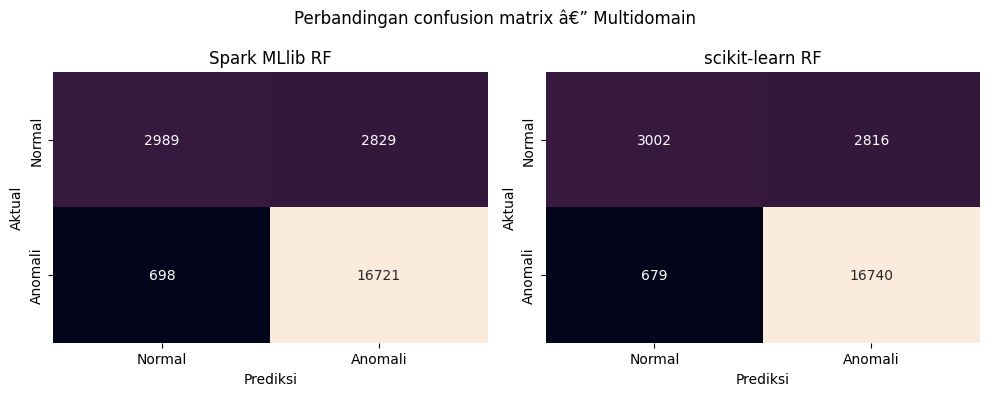

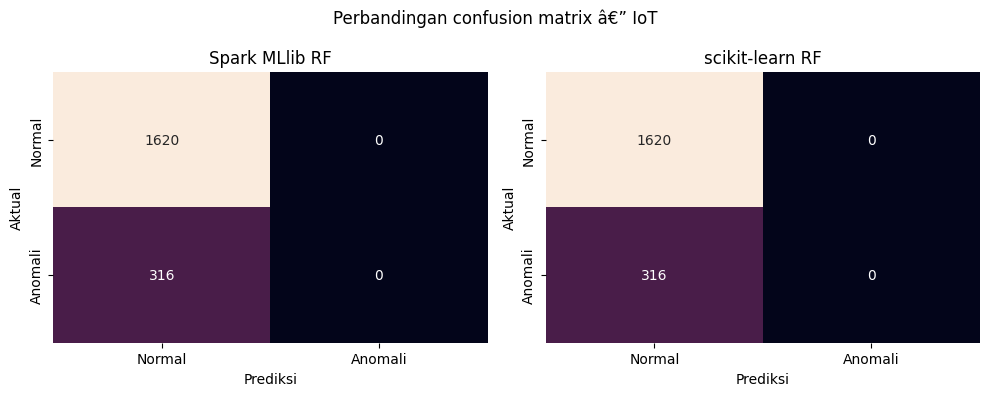

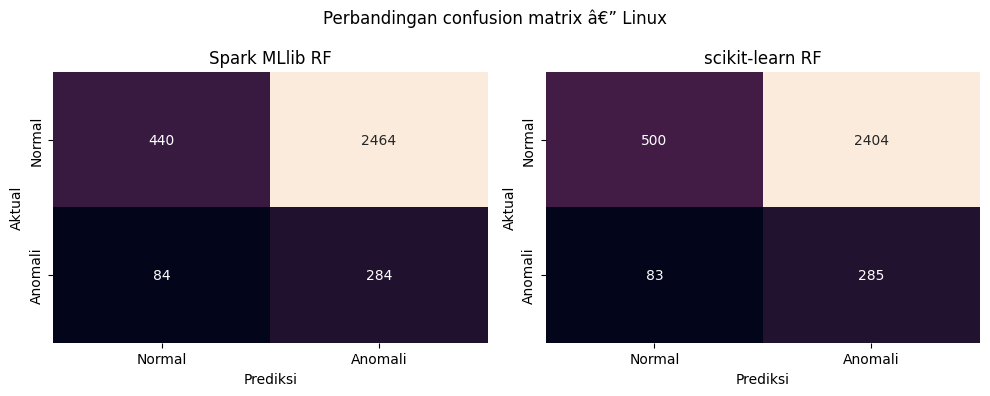

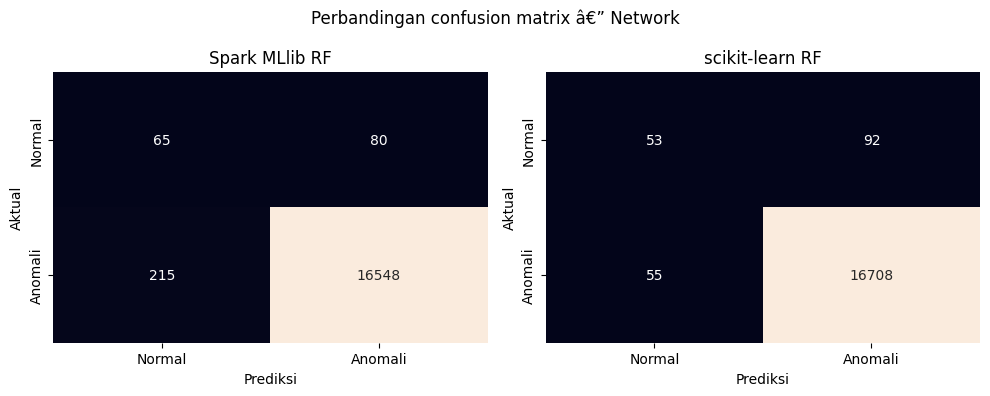

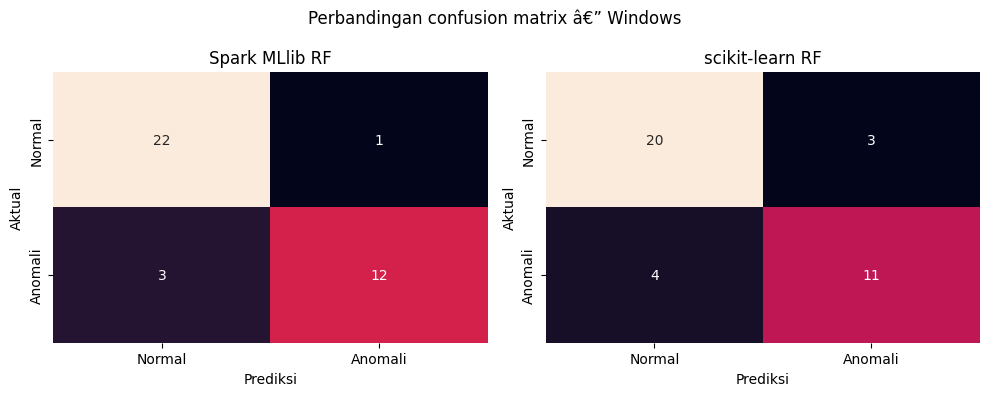

In [53]:
for domain, result in domain_models.items():
    matrices = [("Spark MLlib RF", result["Confusion"]), ("scikit-learn RF", result["Sklearn_Confusion"])]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, (title, matrix) in zip(axes, matrices):
        sns.heatmap(np.asarray(matrix, dtype=int), annot=True, fmt="d", cbar=False,
                    xticklabels=["Normal", "Anomali"], yticklabels=["Normal", "Anomali"], ax=ax)
        ax.set_title(title)
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
    fig.suptitle(f"Perbandingan confusion matrix â€” {domain}")
    plt.tight_layout()
    plt.savefig(f"confusion_matrix_comparison_{domain.lower()}.png", dpi=150)
    plt.show()

In [54]:
anomaly_summary = []
for domain, result in domain_models.items():
    anomaly_summary.extend([
        {"Domain": domain, "Framework": "Spark MLlib â€” K-Means distance",
         "Normal": result["Normal_Count"], "Anomali": result["Anomaly_Count"]},
        {"Domain": domain, "Framework": "scikit-learn â€” Isolation Forest",
         "Normal": result["Sklearn_Normal_Count"], "Anomali": result["Sklearn_Anomaly_Count"]}
    ])
anomaly_summary_df = pd.DataFrame(anomaly_summary)
display(anomaly_summary_df)

,Domain,Framework,Normal,Anomali
0,Multidomain,Spark MLlib â€” K-Means distance,22812,425
1,Multidomain,scikit-learn â€” Isolation Forest,23178,59
2,IoT,Spark MLlib â€” K-Means distance,1936,0
3,IoT,scikit-learn â€” Isolation Forest,1936,0
4,Linux,Spark MLlib â€” K-Means distance,3272,0
5,Linux,scikit-learn â€” Isolation Forest,3264,8
6,Network,Spark MLlib â€” K-Means distance,16838,70
7,Network,scikit-learn â€” Isolation Forest,16829,79
8,Windows,Spark MLlib â€” K-Means distance,36,2
9,Windows,scikit-learn â€” Isolation Forest,36,2


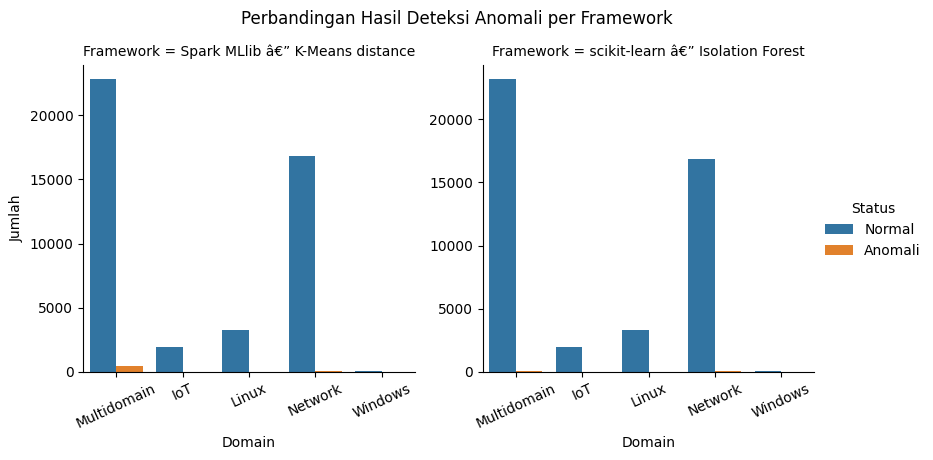

In [55]:
plot_data = anomaly_summary_df.melt(
    id_vars=["Domain", "Framework"], value_vars=["Normal", "Anomali"],
    var_name="Status", value_name="Jumlah"
)
comparison_plot = sns.catplot(
    data=plot_data, x="Domain", y="Jumlah", hue="Status", col="Framework",
    kind="bar", height=4, aspect=1.05, sharey=False
)
comparison_plot.set_xticklabels(rotation=25)
comparison_plot.fig.suptitle("Perbandingan Hasil Deteksi Anomali per Framework", y=1.05)
comparison_plot.savefig("anomaly_detection_framework_comparison.png", dpi=150)
plt.show()

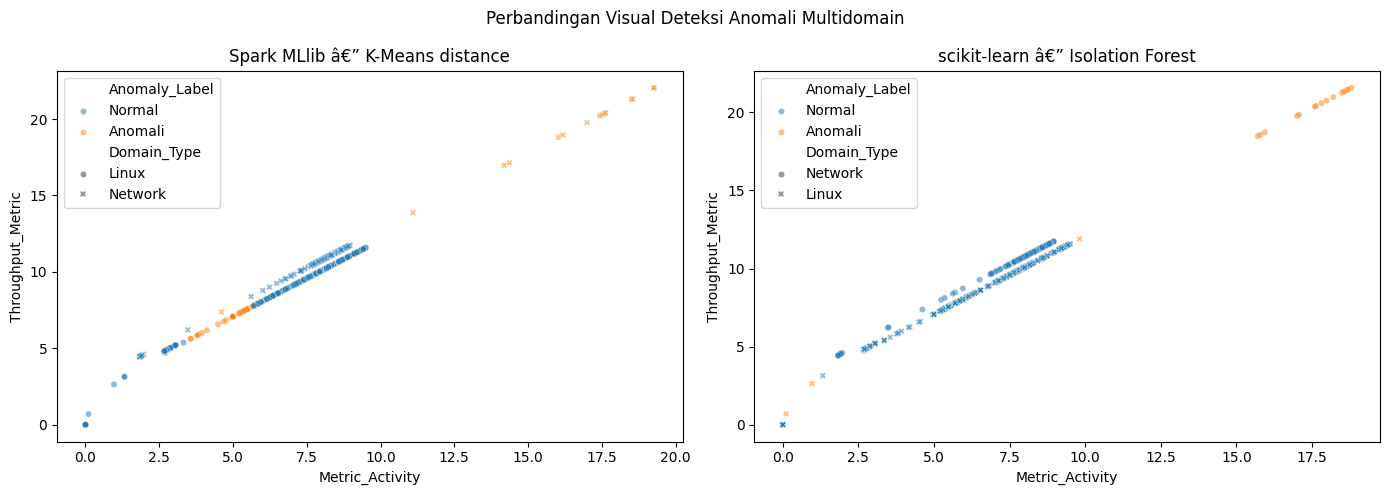

In [56]:
if "Multidomain" in domain_models:
    multi_result = domain_models["Multidomain"]
    spark_plot = multi_result["plot_data"].copy()
    sklearn_plot = multi_result["sklearn_plot_data"].copy()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    if not spark_plot.empty:
        spark_plot["Anomaly_Label"] = np.where(spark_plot["anomaly_prediction"] == 1, "Anomali", "Normal")
        sns.scatterplot(data=spark_plot, x="Metric_Activity", y="Throughput_Metric",
                        hue="Anomaly_Label", style="Domain_Type", alpha=0.5, s=20, ax=axes[0])
    axes[0].set_title("Spark MLlib â€” K-Means distance")
    if not sklearn_plot.empty:
        sklearn_plot["Anomaly_Label"] = np.where(sklearn_plot["IF_Anomaly"] == 1, "Anomali", "Normal")
        style_col = "Domain_Type" if "Domain_Type" in sklearn_plot.columns else None
        sns.scatterplot(data=sklearn_plot, x="Metric_Activity", y="Throughput_Metric",
                        hue="Anomaly_Label", style=style_col, alpha=0.5, s=20, ax=axes[1])
    axes[1].set_title("scikit-learn â€” Isolation Forest")
    fig.suptitle("Perbandingan Visual Deteksi Anomali Multidomain")
    plt.tight_layout()
    plt.savefig("anomaly_detection_multidomain_comparison.png", dpi=150)
    plt.show()
else:
    print("Grafik multidomain dilewati: model belum tersedia.")

In [57]:
conf = spark.sparkContext._jsc.hadoopConfiguration()
fs = spark.sparkContext._gateway.jvm.org.apache.hadoop.fs.FileSystem.get(conf)

print("Hadoop FileSystem Class :", fs.getClass().getName())
print("Hadoop URI Scheme       :", fs.getScheme())
print("Hadoop Working Directory:", str(fs.getWorkingDirectory()))
print("Hadoop Home Directory   :", str(fs.getHomeDirectory()))

Hadoop FileSystem Class : org.apache.hadoop.hdfs.web.WebHdfsFileSystem
Hadoop URI Scheme       : webhdfs
Hadoop Working Directory: webhdfs://10.38.10.84:9870/user/Jase
Hadoop Home Directory   : webhdfs://10.38.10.84:9870/user/Jase


In [58]:
import json
from pathlib import Path

models_dir = Path.cwd() / "models"
models_dir.mkdir(parents=True, exist_ok=True)

export_df = df_clustered.select(
    "Record_ID", "Domain_Type", "System_Region", "Device_Type",
    "Source_File", "Target_Label", "Target_Type", "cluster"
)
if HDFS_ENABLED:
    hdfs_output_path = f"{HDFS_NAMENODE.rstrip('/')}/{HDFS_OUTPUT_DIR.strip('/')}/clustered_parquet"
    export_df.write.mode("overwrite").parquet(hdfs_output_path)
    print(f"Parquet terdistribusi tersimpan di HDFS: {hdfs_output_path}")
else:
    output_file = Path(os.getenv("LOCAL_PARQUET_OUTPUT", "hadoop_clustered_output.parquet"))
    export_df.write.mode("overwrite").parquet(str(output_file))
    print(f"Parquet lokal tersimpan: {output_file.resolve()}")

domains = sorted([
    row["Domain_Type"]
    for row in df_clustered
        .select("Domain_Type")
        .distinct()
        .collect()
])

metadata = {
    "features": feature_cols,
    "random_state": MODEL_RANDOM_STATE,
    "test_size": MODEL_TEST_SIZE,
    "n_estimators": MODEL_N_ESTIMATORS,
    "primary_classifier_mllib": "pyspark.ml.classification.RandomForestClassifier",
    "comparison_classifier_sklearn": "sklearn.ensemble.RandomForestClassifier",
    "comparison_anomaly_sklearn": "sklearn.ensemble.IsolationForest",
    "clustering": "pyspark.ml.clustering.KMeans",
    "anomaly_method": "K-Means squared distance threshold fitted on training data",
    "anomaly_quantile": MODEL_ANOMALY_QUANTILE,
    "frameworks_compared": ["Spark MLlib", "scikit-learn"],
    "comparison_sample_limit": 100000,
    "comparison_split": "same held-out source-file rows or random-row fallback from the shared Spark sample",
    "mapreduce_note": "Spark RDD map/reduce-style aggregation; not Hadoop MapReduce",
    "domains": domains,
    "files": file_summary
}

with open(
    models_dir / "model_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=2,
        default=str
    )

file_summary_df.to_csv(
    "dataset_file_summary.csv",
    index=False
)

evaluation_df.to_csv(
    "model_summary.csv",
    index=False
)

print()
print("=" * 60)
print("FILE MODEL")
print("=" * 60)
print(f"Model directory: {models_dir.resolve()}")
print(f"Metadata        : {(models_dir / 'model_metadata.json').resolve()}")
print(f"Dataset summary : {Path('dataset_file_summary.csv').resolve()}")
print(f"Model summary   : {Path('model_summary.csv').resolve()}")

print()
print("Model:")
for path in sorted(models_dir.glob("*_mllib")):
    print(f"  {path.name}/ (Spark MLlib model artifacts)")
for path in sorted(models_dir.glob("*_sklearn_*.pkl")):
    print(f"  {path.name} (scikit-learn model)")


Parquet terdistribusi tersimpan di HDFS: webhdfs://10.38.10.84:9870/analytics/iot-multidomain/clustered_parquet



FILE MODEL
Model directory: C:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\model\models
Metadata        : C:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\model\models\model_metadata.json
Dataset summary : C:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\model\dataset_file_summary.csv
Model summary   : C:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\model\model_summary.csv

Model:
  iot_mllib/ (Spark MLlib model artifacts)
  linux_mllib/ (Spark MLlib model artifacts)
  multidomain_mllib/ (Spark MLlib model artifacts)
  network_mllib/ (Spark MLlib model artifacts)
  windows_mllib/ (Spark MLlib model artifacts)
  iot_sklearn_attack_type.pkl (scikit-learn model)
  iot_sklearn_isolation_forest.pkl (scikit-learn model)
  iot_sklearn_kmeans.pkl (scikit-learn model)
  iot_sklearn_random_forest.pkl (scikit-learn model)
  iot_sklearn_scaler.pkl (scikit-learn model)
  linux_sklearn_attack_type.pkl (scikit-learn model)
  linux_sklearn_isolation_fore

In [59]:
print("Cakupan dataset:")
display(
    file_summary_df.groupby("domain")
    .agg(files=("file", "nunique"), rows=("rows_used", "sum"))
    .reset_index()
)

print("Evaluasi model:")
display(
    evaluation_df[
        [
            "Domain",
            "Records",
            "Train",
            "Test",
            "Best_K",
            "Train_Silhouette",
            "Test_Silhouette",
            "Accuracy",
            "Precision",
            "Recall",
            "F1"
        ]
    ].sort_values("Domain")
)

print("Semua domain yang tersedia:")
print(sorted(pdf_ml["Domain_Type"].unique().tolist()))

Cakupan dataset:


,domain,files,rows
0,IoT,7,3606134
1,Linux,5,4855329
2,Network,23,21340803
3,Windows,2,64342


Evaluasi model:


,Domain,Records,Train,Test,Best_K,Train_Silhouette,Test_Silhouette,Accuracy,Precision,Recall,F1
1,IoT,12149,10213,1936,2,NaN,NaN,0.836777,0.000000,0.000000,0.000000
2,Linux,16175,12903,3272,2,NaN,NaN,0.221271,0.103348,0.771739,0.182285
0,Multidomain,100400,77163,23237,2,NaN,NaN,0.848216,0.855294,0.959929,0.904596
3,Network,71839,54931,16908,2,NaN,NaN,0.982553,0.995189,0.987174,0.991165
4,Windows,237,199,38,2,NaN,NaN,0.894737,0.923077,0.800000,0.857143


Semua domain yang tersedia:
['IoT', 'Linux', 'Network', 'Windows']
